# QUANT Interval-Selection Experiment Analysis

**How the numbers are built**

1. Only runs with `status == "ok"` are used, and only resamples that succeeded for **every** configuration (so every comparison is paired on identical train/test splits).
2. For each dataset × configuration × classifier, accuracy, feature count and timings are **averaged over the resamples** (timings can switch to the median with `TIME_AGG`).
3. Every configuration is compared to the baseline *within the same dataset*, giving per-dataset accuracy differences, relative error reduction, and feature/time reductions (positive = better than baseline).
4. Datasets are split into size groups (equal-count percentile bins) and into dataset types (Image, Sensor, Motion, ...), and the group analyses are repeated for both, to see where a configuration helps or hurts.

> Use a separate results CSV per configuration. The `run.py` resume key is dataset + resample + classifier, so sharing one output file across configurations can cause runs to be skipped.

# Experiment description

## What experiments are based on
Features in quant are taken as quantile values taken from intervals of the original datasets. Intervals of different sizes are taken for each dataset by taking intervals at different depths. At depth $d$ for any dataset sample, the number of intervals $I_n$ taken from the dataset is calculated as:
$$
I_{n} = d^2
$$
Where the length of each interval $I_n$ for a sample of length $n$ is:

$$
I_n = \frac{n}{2^d}
$$

In the original paper, shift intervals were also taken at each depth. These intervals had the same interval length as the original intervals at this depth, but one less it taken than in the normal intervals, and the interval start position are shifted by half an interval width, as shown below.

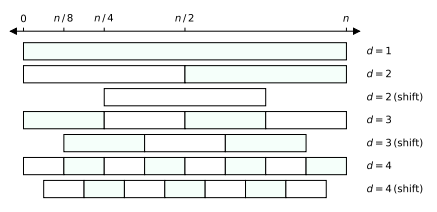

In the orignial paper, intervals were taken at every depth up to a maximum depth $D$ for a sample length $n$ calculated as follows:

$$
D = min(6, log_2 n + 1)
$$

## Experiments Conducted
These experiments involved reducing the number of intervals taken in the original paper by not calculating intervals or their quantile values as certian depths. These experiments conducted are described in the table below. This table also includes the extent of expriements conducted, and intial results.

| Experiment Name | Description | Experiments Conducted | Results |
| --------------- | ----------- | --------------------- | ------- |
| depths_0_5 | Baseline with the same intervals as the original | Ran for all datasets (142) and resamples (30) | N/a |
| no_depth_5 | This test took intervals at the same depths as the baseline without depth 5 intervals. This was done in the original paper and called $QUANT^{FAST}$ | Ran for all datasets (142) and resamples (30) | Minimal accuracy difference across dataset compared to baseline, deemed insignificant according to Friedman and Wilcoxon signed-rank testing and reduced feature count and training time |
| no_depth_4_5 | This test took intervals at the same depths as the baseline without depths 4 and 5 intervals | Ran for all datasets (142) and resamples (30) | Small accuracy difference across dataset compared to baseline, deemed significant according to to Friedman and Wilcoxon signed-rank testing but further reduced feature count and training time compared to origninal and $QUANT^{FAST}$ |
| no_depth_3_4_5 | This test took intervals at the same depths as the baseline without depths 3, 4 and 5 intervals | Ran for all datasets (142) and resamples (30) | More substantial accuracy difference across dataset compared to baseline, deemed significant according to to Friedman and Wilcoxon signed-rank testing and didn't reduce the feature count and training time compared much compared to other methods|
| even_depths | This test took intervals for every second depth value (0, 2, 4) to the same maximum as in the baseline | Ran for all datasets (142) and resamples (30) | Small accuracy difference across dataset compared to baseline, deemed significant according to to Friedman and Wilcoxon signed-rank testing but had the largest feature count and training time reduction compared to origninal and $QUANT^{FAST}$ |
| alternating_depths | This test took normal intervals for every second depth value (0, 2, 4) and shift intervals for every other depth value (1, 3, 5) to the same maximum as in the baseline | Ran for all datasets (142) and resamples (30) | Accuracy reduction across dataset compared to baseline, deemed significant according to to Friedman and Wilcoxon signed-rank testing. Although reasonable feature count and training time reduction, better results came from no_depths_4_5 (better accuracy) and even depths (larger feature reduction), so doesnt warrent further consideration |
| odd_depths | This test took intervals for every second depth value (1, 3, 5) to the same maximum as in the baseline | Ran for all datasets (142) and resamples (30) | Accuracy reduction across dataset compared to baseline, deemed significant according to to Friedman and Wilcoxon signed-rank testing. Although reasonable feature count and training time reduction, better accuracy and feature count reduction camde from other experiments so doesnt warrent further consideration |
| no_depth_0 | This test took intervals at the same depths as the baseline without depth 0 intervals | Ran for all datasets (142) and resamples (30) | Larger reduction in accuracy compared to baseline, deemed significant according to to Friedman and Wilcoxon signed-rank testing and didn't reduce feature count or training time substantially enough to warrent further consideration |
| no_depth_0_1 | This test took intervals at the same depths as the baseline without depths 0 or 1 intervals | Ran for all datasets (142) and resamples (30) | Largest reduction in accuracy compared to baseline, deemed significant according to to Friedman and Wilcoxon signed-rank testing and didn't reduce feature count or training time substantially enough to warrent further consideration |

This also included an analysis removing each depths individually (no_depth_i for i in 0:5). This was done to try to assess the importance of each depth for classification, not in an attempt to improve overall performance.

Further analysis of results can be found at the end of this notebook.

## 1. Configuration

In [53]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display
from scipy import stats

# --- Inputs -----------------------------------------------------------------
RESULTS_DIR = Path("../results")

# CSV filename stem -> display label. Each stem must have <RESULTS_DIR>/<stem>.csv
CONFIG_LABELS = {
    "depths_0_5_baseline": "Baseline (QUANT)",
    "no_depth_5": "Depth 5 excluded (QUANT FAST)",
    "no_depth_4_5": "Depth 4 and 5 excluded",
    #"no_depth_3_4_5": "Depth 3, 4 and 5 excluded",
    #"alternating_depths": "Alternating normal/shift",
    "even_depths": "Even depths (0, 2, 4)",
    #"odd_depths": "Odd depths (1, 3, 5)",
    #"no_depth_0": "Depth 0 excluded",
    #"no_depth_0_1": "Depth 0 and 1 excluded"
}
BASELINE = "Baseline (QUANT)"   # must be one of the labels above

CLASSIFIERS = None                    # e.g. ["extratrees"]; None = all found in the CSVs

# --- Aggregation / statistics -----------------------------------------------
TIME_AGG = "mean"                     # how timings are combined over resamples: "mean" or "median"
TIE_TOL = 1e-12                       # |accuracy difference| below this counts as a tie
N_BOOTSTRAP = 5000                    # bootstrap resamples for the mean-difference confidence interval
ERROR_EPS = 0.001                     # pseudo-error added to BOTH errors in the smoothed error ratio (0.001 = 0.1 pp)
                                      # ideally ~0.5 / n_test; try 0.0005 and 0.002 to check the conclusions do not change
SEED = 0

# --- Dataset-size groups ----------------------------------------------------
N_SIZE_GROUPS = 5                     # equal-count percentile bins (5 = quintiles)
# Optional CSV with one row per dataset: dataset, n_train, series_length[, n_channels]
# (or a single precomputed `size` column). If None, the notebook looks for such
# columns in the results CSVs, and otherwise falls back to a runtime-based proxy.
SIZE_METADATA_CSV = None              # e.g. Path("../dataset_metadata.csv")

# --- Dataset types ----------------------------------------------------------
TYPES_CSV = Path("../improvedQuant/dataSetLists/dataset_types.csv")   # one row per dataset: dataset, type, type_group, ...
TYPE_COLUMN = "type_group"            # "type_group" (rare types merged into Other) or "type" (original archive types)
MIN_DATASETS_PER_GROUP = 8            # groups with fewer datasets get no CD diagram

print("Results directory:", RESULTS_DIR.resolve())

Results directory: C:\Users\davyt\quant-reproduction\results


## 2. Load and validate

Missing or malformed files are reported rather than silently skipped, and the notebook stops if the baseline is not available.

In [54]:
REQUIRED = {
    "dataset", "resample", "classifier", "accuracy", "status", "n_features",
    "time_transform_train", "time_fit", "time_transform_test", "time_predict",
}
NUMERIC = [
    "accuracy", "balanced_accuracy", "n_features",
    "time_transform_train", "time_fit", "time_transform_test", "time_predict",
]

frames, load_issues = [], []
for stem, label in CONFIG_LABELS.items():
    path = RESULTS_DIR / f"{stem}.csv"
    try:
        frame = pd.read_csv(path)
    except Exception as exc:
        load_issues.append({"file": str(path), "issue": f"Could not read: {exc}"})
        continue
    missing = sorted(REQUIRED - set(frame.columns))
    if missing:
        load_issues.append({"file": str(path), "issue": "Missing columns: " + ", ".join(missing)})
        continue
    frame["configuration"] = label
    for col in NUMERIC:
        frame[col] = pd.to_numeric(frame[col], errors="coerce") if col in frame else np.nan
    frame["resample"] = pd.to_numeric(frame["resample"], errors="coerce")
    frame["status"] = frame["status"].fillna("").astype(str)
    frames.append(frame)

if load_issues:
    display(pd.DataFrame(load_issues))
if not frames:
    raise FileNotFoundError("No usable result CSVs found. Check RESULTS_DIR and CONFIG_LABELS.")

results = pd.concat(frames, ignore_index=True, sort=False)
if BASELINE not in set(results["configuration"]):
    raise ValueError(f"Baseline '{BASELINE}' was not loaded. Loaded: {sorted(results['configuration'].unique())}")
if CLASSIFIERS is not None:
    results = results[results["classifier"].isin(CLASSIFIERS)].copy()

# Duplicated runs would double-count a resample, so keep the first and say so.
run_key = ["configuration", "dataset", "classifier", "resample"]
n_dup = int(results.duplicated(run_key).sum())
if n_dup:
    print(f"WARNING: dropped {n_dup} duplicated runs (same configuration/dataset/classifier/resample).")
    results = results.drop_duplicates(run_key, keep="first")

results["is_success"] = results["status"].str.lower().eq("ok") & results["accuracy"].notna()

print(f"Loaded {len(results):,} runs from {len(frames)} file(s); "
      f"{int(results['is_success'].sum()):,} successful.")
display(
    results.groupby(["configuration", "classifier", "status"]).size()
    .rename("runs").reset_index()
)

Loaded 17,040 runs from 4 file(s); 17,040 successful.


,configuration,classifier,status,runs
0,Baseline (QUANT),extratrees,ok,4260
1,Depth 4 and 5 excluded,extratrees,ok,4260
2,Depth 5 excluded (QUANT FAST),extratrees,ok,4260
3,"Even depths (0, 2, 4)",extratrees,ok,4260


## 3. Paired runs and per-dataset averages

A resample is kept only if the same dataset/classifier/resample succeeded in **all** configurations, so every configuration is averaged over the same splits. The table `table` has one row per dataset × configuration × classifier and is used by everything below.

In [55]:
ok = results.loc[results["is_success"]].copy()
ok["time_train_total"] = ok["time_transform_train"] + ok["time_fit"]
ok["time_test_total"] = ok["time_transform_test"] + ok["time_predict"]

# Keep only resamples that succeeded in every configuration.
all_configs = sorted(ok["configuration"].unique())
pair_key = ["dataset", "classifier", "resample"]
n_cfg = ok.groupby(pair_key)["configuration"].transform("nunique")
paired = ok.loc[n_cfg == len(all_configs)].copy()
print(f"Configurations: {all_configs}")
print(f"Successful runs: {len(ok):,} -> kept {len(paired):,} runs in complete resample sets "
      f"({len(ok) - len(paired):,} dropped).")

TIME_COLS = ["time_transform_train", "time_fit", "time_transform_test", "time_predict",
             "time_train_total", "time_test_total"]
agg_spec = {
    "accuracy": ("accuracy", "mean"),
    "balanced_accuracy": ("balanced_accuracy", "mean"),
    "n_features": ("n_features", "mean"),
    "n_resamples": ("resample", "nunique"),
}
agg_spec.update({c: (c, TIME_AGG) for c in TIME_COLS})

table = (
    paired.groupby(["dataset", "classifier", "configuration"], as_index=False)
    .agg(**agg_spec)
)
table["error"] = 1 - table["accuracy"]

# Coverage check: every dataset should appear in every configuration with the same resample count.
cov = table.groupby(["classifier", "configuration"]).agg(
    datasets=("dataset", "nunique"),
    resamples_min=("n_resamples", "min"),
    resamples_median=("n_resamples", "median"),
    resamples_max=("n_resamples", "max"),
)
display(cov)
print(f"{table['dataset'].nunique()} datasets in the analysis table.")

Configurations: ['Baseline (QUANT)', 'Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)']
Successful runs: 17,040 -> kept 17,040 runs in complete resample sets (0 dropped).


datasets  resamples_min  resamples_median  resamples_max
classifier configuration                                                                          
extratrees Baseline (QUANT)                    142             30              30.0             30
           Depth 4 and 5 excluded              142             30              30.0             30
           Depth 5 excluded (QUANT FAST)       142             30              30.0             30
           Even depths (0, 2, 4)               142             30              30.0             30

142 datasets in the analysis table.


## 4. Dataset-size groups

QUANT's cost scales with the number of training cases × series length × channels, so that is the preferred size measure. The notebook uses, in order:

1. `SIZE_METADATA_CSV` (or columns in the results CSVs) with `n_train` and `series_length` (and optionally `n_channels`);
2. a single `size` column, if present;
3. otherwise a **runtime proxy**: the geometric mean of `time_transform_train` across configurations. This is a reasonable stand-in for data volume, but it is measured, so noisy timings can nudge a dataset into a neighbouring group. Use real metadata for anything you plan to publish.

Groups are equal-count percentile bins (`N_SIZE_GROUPS`), so each group has roughly the same number of datasets.

In [56]:
SIZE_ALIASES = {
    "n_train": ["n_train", "n_train_cases", "n_cases_train", "train_size"],
    "length": ["series_length", "n_timepoints", "n_timesteps", "length"],
    "channels": ["n_channels", "n_dimensions", "n_dims"],
    "size": ["size", "dataset_size"],
}

def find_col(df, key):
    return next((c for c in SIZE_ALIASES[key] if c in df.columns), None)

def size_from_frame(df):
    # Return (Series indexed by dataset, description) or None if no usable columns.
    per_dataset = df.groupby("dataset").first()
    n_train, length, chans = (find_col(per_dataset, k) for k in ("n_train", "length", "channels"))
    if n_train and length:
        size = per_dataset[n_train] * per_dataset[length]
        if chans:
            size = size * per_dataset[chans].fillna(1)
        return size, "n_train × series_length" + (" × n_channels" if chans else "")
    size_col = find_col(per_dataset, "size")
    if size_col:
        return per_dataset[size_col], size_col
    return None

size_info = None
if SIZE_METADATA_CSV is not None:
    size_info = size_from_frame(pd.read_csv(SIZE_METADATA_CSV))
    if size_info is None:
        raise ValueError("SIZE_METADATA_CSV needs n_train + series_length columns, or a `size` column.")
if size_info is None:
    size_info = size_from_frame(results)

if size_info is not None:
    dataset_size, SIZE_DESC = size_info
    dataset_size = dataset_size.reindex(table["dataset"].unique())
    if dataset_size.isna().any():
        raise ValueError(f"No size for datasets: {list(dataset_size.index[dataset_size.isna()])[:10]}")
else:
    SIZE_DESC = "runtime proxy (geometric mean of training-transform time, s)"
    dataset_size = (
        table.groupby("dataset")["time_transform_train"]
        .apply(lambda s: float(np.exp(np.log(s.clip(lower=1e-9)).mean())))
    )
    print("NOTE: no dataset-size metadata found, using a runtime proxy for size groups.")

dataset_size = dataset_size.astype(float).sort_values()
# Rank first so ties can't collapse bins; groups end up equal-sized (±1 dataset).
bin_id = pd.qcut(dataset_size.rank(method="first"), N_SIZE_GROUPS, labels=False)

group_label = {}
for g in range(N_SIZE_GROUPS):
    members = dataset_size[bin_id == g]
    lo_pct, hi_pct = round(100 * g / N_SIZE_GROUPS), round(100 * (g + 1) / N_SIZE_GROUPS)
    group_label[g] = f"G{g + 1}: {lo_pct}–{hi_pct}th pct  (size {members.min():.3g}–{members.max():.3g}, n={len(members)})"

GROUP_ORDER = [group_label[g] for g in range(N_SIZE_GROUPS)]
dataset_group = bin_id.map(group_label)
table["size_group"] = pd.Categorical(table["dataset"].map(dataset_group), categories=GROUP_ORDER, ordered=True)

print("Size measure:", SIZE_DESC)
display(dataset_group.value_counts().reindex(GROUP_ORDER).rename("datasets").rename_axis("size group").to_frame())

NOTE: no dataset-size metadata found, using a runtime proxy for size groups.
Size measure: runtime proxy (geometric mean of training-transform time, s)


,datasets
size group,
"G1: 0–20th pct (size 0.0104–0.0488, n=29)",29
"G2: 20–40th pct (size 0.0493–0.075, n=28)",28
"G3: 40–60th pct (size 0.0758–0.123, n=28)",28
"G4: 60–80th pct (size 0.125–0.193, n=28)",28
"G5: 80–100th pct (size 0.221–1.83, n=29)",29


## 4b. Dataset types

Datasets are also grouped by **type** (Image, Sensor, Motion, Device, ECG, Simulated, Spectro, ...), using the types from the UCR/TSC archive. `dataset_types.csv` has one row per dataset with the original archive `type` and a coarser `type_group`, in which the rare types (EOG, EPG, HRM, Hemodynamics, Power, Spectrum, Traffic, Trajectory) are merged into **Other** so every group has enough datasets to analyse. Set `TYPE_COLUMN = "type"` to use the original types instead.

Names ending in `_eq` (equal-length versions of unequal-length datasets) are matched to the base dataset name. Datasets that are not in the CSV are grouped as **Unknown** and listed below so you can add them.

Every group analysis below (sections 6b, 6c, 9, 10a, 10b) runs once per grouping in `GROUPINGS`: dataset size and dataset type.

In [57]:
types_df = pd.read_csv(TYPES_CSV)
type_map = dict(zip(types_df["dataset"], types_df[TYPE_COLUMN]))

def lookup_type(name):
    base = name[:-3] if name.endswith("_eq") else name
    return type_map.get(name, type_map.get(base, "Unknown"))

dataset_type = pd.Series({d: lookup_type(d) for d in table["dataset"].unique()})
unknown = sorted(dataset_type.index[dataset_type == "Unknown"])
if unknown:
    print(f"{len(unknown)} dataset(s) not found in {TYPES_CSV.name} (grouped as 'Unknown'; add them to the CSV):")
    print(", ".join(unknown))

counts_by_type = dataset_type.value_counts()
# Largest types first; "Other" and "Unknown" last.
TYPE_NAMES = (
    [t for t in counts_by_type.index if t not in ("Other", "Unknown")]
    + [t for t in ("Other", "Unknown") if t in counts_by_type.index]
)
type_label = {t: f"{t} (n={counts_by_type[t]})" for t in TYPE_NAMES}
TYPE_ORDER = [type_label[t] for t in TYPE_NAMES]
dataset_type_group = dataset_type.map(type_label)
table["type_group"] = pd.Categorical(table["dataset"].map(dataset_type_group), categories=TYPE_ORDER, ordered=True)

# Every group analysis below runs once per grouping: label -> (column in the tables, ordered group names).
GROUPINGS = {
    "size group": ("size_group", GROUP_ORDER),
    "dataset type": ("type_group", TYPE_ORDER),
}
dataset_groups = {"size_group": dataset_group, "type_group": dataset_type_group}   # column -> (dataset -> group name)

small = [t for t in TYPE_NAMES if counts_by_type[t] < MIN_DATASETS_PER_GROUP]
if small:
    print(f"Note: types with fewer than {MIN_DATASETS_PER_GROUP} datasets get no CD diagram: {small}")
display(counts_by_type.reindex(TYPE_NAMES).rename("datasets").rename_axis("type").to_frame())

19 dataset(s) not found in dataset_types.csv (grouped as 'Unknown'; add them to the CSV):
AconityMINIPrinterLarge_eq, AconityMINIPrinterSmall_eq, AsphaltObstaclesUni_eq, AsphaltPavementTypeUni_eq, AsphaltRegularityUni_eq, Colposcopy, Covid3Month_disc, DodgerLoopDay_nmv, DodgerLoopGame_nmv, DodgerLoopWeekend_nmv, ElectricDeviceDetection, FloodModeling1_disc, FloodModeling2_disc, FloodModeling3_disc, KeplerLightCurves, MelbournePedestrian_nmv, PhoneHeartbeatSound, SharePriceIncrease, Tools
Note: types with fewer than 8 datasets get no CD diagram: ['ECG']


,datasets
type,
Image,32
Sensor,27
Motion,17
Device,9
Simulated,8
Spectro,8
ECG,6
Other,16
Unknown,19


## 5. Per-dataset comparison with the baseline

For each non-baseline configuration and dataset (all values positive = better than baseline unless noted):

- **Accuracy difference** (percentage points): $\Delta A = A_{\text{new}} - A_{\text{baseline}}$
- **Relative error reduction** (%): $\dfrac{E_{\text{baseline}} - E_{\text{new}}}{E_{\text{baseline}}}$, where $E = 1 - A$. This is **undefined when the baseline error is 0** (a perfect baseline), so those datasets are left out of this one metric (reported below) instead of producing `-inf`/`NaN`.
- **Smoothed error ratio**: $\dfrac{E_{\text{new}} + \varepsilon}{E_{\text{baseline}} + \varepsilon}$ with a small pseudo-error $\varepsilon$ (`ERROR_EPS`) added to both errors, averaged on the log scale (geometric mean). Unlike relative error reduction it is defined for perfect baselines and cannot be dominated by one or two test-case errors on a near-perfect dataset. 1.0 = no change, 1.2 = 20% more error.
- **Feature, training-time and test-time reduction** (%): $\dfrac{X_{\text{baseline}} - X_{\text{new}}}{X_{\text{baseline}}}$. Training time is `time_transform_train + time_fit`; test time is `time_transform_test + time_predict`.

In [58]:
BASE_COLS = ["accuracy", "error", "n_features", "time_train_total", "time_test_total"]

base = (
    table.loc[table["configuration"] == BASELINE]
    .set_index(["dataset", "classifier"])[BASE_COLS]
    .add_prefix("base_")
)
cmp = table.loc[table["configuration"] != BASELINE].join(base, on=["dataset", "classifier"])
cmp = cmp.dropna(subset=["base_accuracy"]).copy()

def pct_reduction(new, old):
    return 100 * (old - new) / old.where(old > 0)      # NaN where the baseline value is 0

cmp["acc_diff_pp"] = 100 * (cmp["accuracy"] - cmp["base_accuracy"])
cmp["error_reduction_pct"] = pct_reduction(cmp["error"], cmp["base_error"])
# Smoothed error ratio: the pseudo-error ERROR_EPS stops one or two test-case errors on a near-perfect
# baseline from producing a huge ratio. log2 makes "doubled" (+1) and "halved" (-1) symmetric.
cmp["log2_error_ratio"] = np.log2((cmp["error"] + ERROR_EPS) / (cmp["base_error"] + ERROR_EPS))
cmp["feature_reduction_pct"] = pct_reduction(cmp["n_features"], cmp["base_n_features"])
cmp["train_time_reduction_pct"] = pct_reduction(cmp["time_train_total"], cmp["base_time_train_total"])
cmp["test_time_reduction_pct"] = pct_reduction(cmp["time_test_total"], cmp["base_time_test_total"])

excluded = (
    cmp.assign(perfect_baseline=cmp["base_error"] <= 0)
    .groupby(["classifier", "configuration"])["perfect_baseline"].sum()
    .rename("datasets excluded from error reduction (baseline accuracy = 100%)")
)
display(excluded.to_frame())

COMPARE_CONFIGS = sorted(cmp["configuration"].unique())
palette = plt.get_cmap("tab10")
CONFIG_COLORS = {BASELINE: "#7f7f7f"}
CONFIG_COLORS.update({c: palette(i) for i, c in enumerate(COMPARE_CONFIGS)})
classifiers = sorted(table["classifier"].unique())

datasets excluded from error reduction (baseline accuracy = 100%)
classifier configuration                                                                                   
extratrees Depth 4 and 5 excluded                                                         5                
           Depth 5 excluded (QUANT FAST)                                                  5                
           Even depths (0, 2, 4)                                                          5

## 6. Summary statistics

Each row summarises one configuration against the baseline across datasets. Besides means and medians it reports:

- **improved / tied / declined**: datasets where the (averaged) accuracy went up, stayed within `TIE_TOL`, or went down;
- **95% CI**: bootstrap confidence interval for the mean accuracy difference (resampling datasets);
- **Wilcoxon p**: paired two-sided signed-rank test on the per-dataset accuracy differences (ties dropped). With several configurations and size groups you are making many comparisons, so treat isolated small p-values with caution and prefer the CI and the effect size.

In [59]:
rng = np.random.default_rng(SEED)

def bootstrap_ci(values, n_boot=N_BOOTSTRAP, alpha=0.05):
    values = np.asarray(values, dtype=float)
    if len(values) < 2:
        return np.nan, np.nan
    idx = rng.integers(0, len(values), size=(n_boot, len(values)))
    means = values[idx].mean(axis=1)
    return tuple(np.quantile(means, [alpha / 2, 1 - alpha / 2]))

def wilcoxon_p(diffs):
    nonzero = diffs[np.abs(diffs) > TIE_TOL]
    if len(nonzero) < 6:                      # too few non-tied datasets for a meaningful test
        return np.nan
    return stats.wilcoxon(nonzero).pvalue

def summarise(frame, group_cols):
    rows = []
    for keys, g in frame.groupby(group_cols, observed=True):
        keys = keys if isinstance(keys, tuple) else (keys,)
        d = g["acc_diff_pp"].to_numpy()
        diff_frac = d / 100
        ci_lo, ci_hi = bootstrap_ci(d)
        rows.append({
            **dict(zip(group_cols, keys)),
            "datasets": len(g),
            "acc diff mean (pp)": d.mean(),
            "95% CI": f"[{ci_lo:.2f}, {ci_hi:.2f}]",
            "acc diff median (pp)": np.median(d),
            "improved": int((diff_frac > TIE_TOL).sum()),
            "tied": int((np.abs(diff_frac) <= TIE_TOL).sum()),
            "declined": int((diff_frac < -TIE_TOL).sum()),
            "Wilcoxon p": wilcoxon_p(diff_frac),
            "error red. mean (%)": g["error_reduction_pct"].mean(),
            "error red. median (%)": g["error_reduction_pct"].median(),
            "error red. n": int(g["error_reduction_pct"].notna().sum()),
            "smoothed error ratio (geo. mean)": 2 ** g["log2_error_ratio"].mean(),
            "feature red. mean (%)": g["feature_reduction_pct"].mean(),
            "train time red. mean (%)": g["train_time_reduction_pct"].mean(),
            "train time red. median (%)": g["train_time_reduction_pct"].median(),
            "test time red. mean (%)": g["test_time_reduction_pct"].mean(),
            "test time red. median (%)": g["test_time_reduction_pct"].median(),
        })
    return pd.DataFrame(rows)

def show(summary):
    pd.set_option("display.width", 250, "display.max_columns", None)
    display(
        summary.style.format(
            {c: "{:.2f}" for c in summary.columns if c.endswith(("(pp)", "(%)"))} | {"Wilcoxon p": "{:.4f}"},
            na_rep="–",
        ).hide(axis="index")
    )

### 6a. Overall (all datasets)

In [60]:
overall = summarise(cmp, ["classifier", "configuration"])
show(overall)

classifier,configuration,datasets,acc diff mean (pp),95% CI,acc diff median (pp),improved,tied,declined,Wilcoxon p,error red. mean (%),error red. median (%),error red. n,smoothed error ratio (geo. mean),feature red. mean (%),train time red. mean (%),train time red. median (%),test time red. mean (%),test time red. median (%)
extratrees,Depth 4 and 5 excluded,142,-0.23,"[-0.43, -0.06]",-0.02,58,6,78,0.0302,-4.83,-0.52,137,1.040816,41.13,28.89,26.94,44.07,44.65
extratrees,Depth 5 excluded (QUANT FAST),142,-0.05,"[-0.13, 0.02]",0.00,67,11,64,0.3439,-0.10,0.00,137,1.009953,21.17,16.58,16.94,26.02,25.94
extratrees,"Even depths (0, 2, 4)",142,-0.23,"[-0.35, -0.12]",-0.10,57,5,80,0.0001,-11.20,-0.97,137,1.045674,53.98,33.10,31.62,48.18,48.77


### 6b. By group (dataset size and dataset type)

In [61]:
for grouping, (col, order) in GROUPINGS.items():
    print(f"\n=== By {grouping} ===")
    show(summarise(cmp, ["classifier", col, "configuration"]))


=== By size group ===


classifier,size_group,configuration,datasets,acc diff mean (pp),95% CI,acc diff median (pp),improved,tied,declined,Wilcoxon p,error red. mean (%),error red. median (%),error red. n,smoothed error ratio (geo. mean),feature red. mean (%),train time red. mean (%),train time red. median (%),test time red. mean (%),test time red. median (%)
extratrees,"G1: 0–20th pct (size 0.0104–0.0488, n=29)",Depth 4 and 5 excluded,29,-0.31,"[-0.57, -0.09]",-0.10,8,2,19,0.0229,-11.71,-3.57,27,1.108594,40.05,17.29,19.89,37.39,42.30
extratrees,"G1: 0–20th pct (size 0.0104–0.0488, n=29)",Depth 5 excluded (QUANT FAST),29,-0.08,"[-0.19, 0.02]",0.00,10,6,13,0.1793,2.63,0.00,27,1.017817,20.12,10.76,12.14,22.64,23.89
extratrees,"G1: 0–20th pct (size 0.0104–0.0488, n=29)","Even depths (0, 2, 4)",29,-0.25,"[-0.49, -0.03]",-0.03,12,2,15,0.1056,-13.58,-1.16,27,1.101622,53.85,19.21,20.75,44.35,47.16
extratrees,"G2: 20–40th pct (size 0.0493–0.075, n=28)",Depth 4 and 5 excluded,28,-0.50,"[-1.18, -0.08]",-0.01,11,2,15,0.0709,-8.96,-0.77,26,1.058611,44.23,23.41,21.28,43.58,41.39
extratrees,"G2: 20–40th pct (size 0.0493–0.075, n=28)",Depth 5 excluded (QUANT FAST),28,-0.19,"[-0.43, 0.03]",-0.06,11,3,14,0.1199,-2.69,-1.14,26,1.025014,23.17,13.62,11.60,26.93,24.47
extratrees,"G2: 20–40th pct (size 0.0493–0.075, n=28)","Even depths (0, 2, 4)",28,-0.30,"[-0.70, -0.02]",-0.11,10,2,16,0.0669,-15.85,-0.61,26,1.060720,54.49,22.63,22.83,43.79,44.53
extratrees,"G3: 40–60th pct (size 0.0758–0.123, n=28)",Depth 4 and 5 excluded,28,-0.34,"[-0.76, 0.03]",-0.02,12,1,15,0.3242,-2.23,-0.62,27,1.015736,41.06,26.17,25.71,44.68,42.24
extratrees,"G3: 40–60th pct (size 0.0758–0.123, n=28)",Depth 5 excluded (QUANT FAST),28,-0.14,"[-0.33, 0.04]",-0.02,10,2,16,0.2173,-0.81,-0.44,27,1.007830,21.37,17.16,17.22,27.91,29.24
extratrees,"G3: 40–60th pct (size 0.0758–0.123, n=28)","Even depths (0, 2, 4)",28,-0.35,"[-0.60, -0.12]",-0.13,10,1,17,0.0319,-26.44,-1.15,27,1.050351,54.11,30.98,31.04,49.62,49.08
extratrees,"G4: 60–80th pct (size 0.125–0.193, n=28)",Depth 4 and 5 excluded,28,-0.04,"[-0.34, 0.24]",0.10,16,1,11,0.8223,-0.23,0.68,28,1.010185,40.71,33.49,32.47,45.14,47.49



=== By dataset type ===


classifier,type_group,configuration,datasets,acc diff mean (pp),95% CI,acc diff median (pp),improved,tied,declined,Wilcoxon p,error red. mean (%),error red. median (%),error red. n,smoothed error ratio (geo. mean),feature red. mean (%),train time red. mean (%),train time red. median (%),test time red. mean (%),test time red. median (%)
extratrees,Image (n=32),Depth 4 and 5 excluded,32,-0.21,"[-0.42, -0.02]",-0.07,14,0,18,0.1195,-2.31,-0.55,32,1.021236,42.99,26.96,25.08,43.38,41.95
extratrees,Image (n=32),Depth 5 excluded (QUANT FAST),32,-0.11,"[-0.23, 0.02]",-0.09,13,1,18,0.1066,-1.09,-0.96,32,1.010276,22.09,13.87,12.27,23.78,21.57
extratrees,Image (n=32),"Even depths (0, 2, 4)",32,-0.22,"[-0.39, -0.05]",-0.17,13,0,19,0.0394,-2.13,-1.49,32,1.019785,54.14,29.78,27.60,45.65,46.71
extratrees,Sensor (n=27),Depth 4 and 5 excluded,27,-0.29,"[-0.64, 0.01]",-0.10,11,1,15,0.1165,-1.31,-0.82,26,1.032404,40.87,27.45,28.05,45.03,45.97
extratrees,Sensor (n=27),Depth 5 excluded (QUANT FAST),27,-0.11,"[-0.30, 0.06]",0.00,12,2,13,0.4742,2.23,-0.12,26,1.002819,21.12,16.66,17.94,26.75,28.06
extratrees,Sensor (n=27),"Even depths (0, 2, 4)",27,-0.20,"[-0.41, -0.01]",-0.07,10,1,16,0.0525,-4.51,-0.78,26,1.038473,53.91,32.57,32.18,50.16,49.52
extratrees,Motion (n=17),Depth 4 and 5 excluded,17,0.06,"[-0.13, 0.25]",0.03,9,1,7,0.6322,-4.29,0.68,16,1.023421,42.26,30.08,28.93,42.97,41.38
extratrees,Motion (n=17),Depth 5 excluded (QUANT FAST),17,0.06,"[-0.08, 0.19]",0.07,11,1,5,0.2979,-0.68,0.73,16,1.008932,22.40,18.37,17.09,27.12,26.32
extratrees,Motion (n=17),"Even depths (0, 2, 4)",17,-0.14,"[-0.37, 0.06]",-0.16,7,1,9,0.4332,-23.42,-0.62,16,1.080143,54.38,36.68,37.91,52.12,49.57
extratrees,Device (n=9),Depth 4 and 5 excluded,9,0.34,"[-0.03, 0.81]",0.09,6,1,2,0.1484,1.71,0.72,9,0.982497,40.76,40.93,41.22,51.20,50.39


### 6c. Mean differences per group (compact tables)

The same quantities as the original per-metric tables (mean accuracy gain, mean relative error reduction, smoothed error ratio, mean feature/training/test-time reduction, and the improved / stayed the same / declined counts), with one row per group, for dataset size and then for dataset type. The last row of each block, **All datasets**, is the overall figure. Positive = better than the baseline (except the smoothed error ratio: above 1 = more error). Relative error reduction excludes datasets with a perfect baseline (undefined), so it never produces `-inf`.

In [62]:
ALL = "All datasets"

MEAN_TABLES = {
    "Mean accuracy gain (percentage points)": "acc_diff_pp",
    "Mean relative error reduction (%)": "error_reduction_pct",
    "Mean feature count reduction (%)": "feature_reduction_pct",
    "Mean training time reduction (%)": "train_time_reduction_pct",
    "Mean test time reduction (%)": "test_time_reduction_pct",
}

def ordered(table_, levels):
    # Rows in classifier -> group order ("All datasets" last); drops combinations that do not exist.
    full = pd.MultiIndex.from_product(levels, names=table_.index.names)
    return table_.reindex(full).dropna(how="all")

def compact_tables(col, order):
    cmp_all = pd.concat(
        [cmp.assign(**{col: cmp[col].astype(str)}), cmp.assign(**{col: ALL})], ignore_index=True
    )
    row_order = list(order) + [ALL]

    for title, metric in MEAN_TABLES.items():
        t = cmp_all.pivot_table(index=["classifier", col], columns="configuration",
                                values=metric, aggfunc="mean")[COMPARE_CONFIGS]
        print(f"\n{title}:")
        display(ordered(t, [classifiers, row_order]).round(3))

    # Smoothed error ratio (geometric mean): 1.0 = same error as baseline, >1 = more error, <1 = less.
    t = 2 ** cmp_all.pivot_table(index=["classifier", col], columns="configuration",
                                 values="log2_error_ratio", aggfunc="mean")[COMPARE_CONFIGS]
    print(f"\nSmoothed error ratio, geometric mean (ERROR_EPS = {ERROR_EPS}; >1 = more error than baseline):")
    display(ordered(t, [classifiers, row_order]).round(3))

    # Improved / stayed the same / declined (tolerance TIE_TOL on the accuracy difference)
    diff = cmp_all["acc_diff_pp"] / 100
    cmp_all["result"] = np.select([diff > TIE_TOL, diff < -TIE_TOL], ["Improved", "Declined"], "Stayed the same")
    counts = (
        cmp_all.groupby(["classifier", col, "configuration"])["result"].value_counts()
        .unstack(fill_value=0)
        .reindex(columns=["Improved", "Stayed the same", "Declined"], fill_value=0)
    )
    counts = counts.reindex(
        pd.MultiIndex.from_product([classifiers, row_order, COMPARE_CONFIGS], names=counts.index.names)
    ).dropna(how="all").astype(int)
    print("\nNumber of dataset comparisons (accuracy vs baseline):")
    display(counts)

for grouping, (col, order) in GROUPINGS.items():
    print(f"\n{'=' * 25} By {grouping} {'=' * 25}")
    compact_tables(col, order)


========================= By size group =========================

Mean accuracy gain (percentage points):


configuration                                          Depth 4 and 5 excluded  Depth 5 excluded (QUANT FAST)  Even depths (0, 2, 4)
classifier size_group                                                                                                              
extratrees G1: 0–20th pct  (size 0.0104–0.0488, n=29)                  -0.311                         -0.083                 -0.246
           G2: 20–40th pct  (size 0.0493–0.075, n=28)                  -0.499                         -0.189                 -0.302
           G3: 40–60th pct  (size 0.0758–0.123, n=28)                  -0.335                         -0.137                 -0.355
           G4: 60–80th pct  (size 0.125–0.193, n=28)                   -0.035                          0.059                 -0.022
           G5: 80–100th pct  (size 0.221–1.83, n=29)                    0.014                          0.092                 -0.242
           All datasets                                                -0.232                         -0.051                 -0.234


Mean relative error reduction (%):


configuration                                          Depth 4 and 5 excluded  Depth 5 excluded (QUANT FAST)  Even depths (0, 2, 4)
classifier size_group                                                                                                              
extratrees G1: 0–20th pct  (size 0.0104–0.0488, n=29)                 -11.708                          2.634                -13.578
           G2: 20–40th pct  (size 0.0493–0.075, n=28)                  -8.961                         -2.694                -15.849
           G3: 40–60th pct  (size 0.0758–0.123, n=28)                  -2.225                         -0.814                -26.440
           G4: 60–80th pct  (size 0.125–0.193, n=28)                   -0.234                          0.250                  0.658
           G5: 80–100th pct  (size 0.221–1.83, n=29)                   -1.585                         -0.009                 -2.057
           All datasets                                                -4.830                         -0.104                -11.196


Mean feature count reduction (%):


configuration                                          Depth 4 and 5 excluded  Depth 5 excluded (QUANT FAST)  Even depths (0, 2, 4)
classifier size_group                                                                                                              
extratrees G1: 0–20th pct  (size 0.0104–0.0488, n=29)                  40.045                         20.117                 53.850
           G2: 20–40th pct  (size 0.0493–0.075, n=28)                  44.232                         23.166                 54.486
           G3: 40–60th pct  (size 0.0758–0.123, n=28)                  41.056                         21.372                 54.112
           G4: 60–80th pct  (size 0.125–0.193, n=28)                   40.707                         21.101                 54.006
           G5: 80–100th pct  (size 0.221–1.83, n=29)                   39.708                         20.192                 53.479
           All datasets                                                41.132                         21.175                 53.982

... (18 outputs left out)


Smoothed error ratio, geometric mean (ERROR_EPS = 0.001; >1 = more error than baseline):


configuration               Depth 4 and 5 excluded  Depth 5 excluded (QUANT FAST)  Even depths (0, 2, 4)
classifier type_group                                                                                   
extratrees Image (n=32)                      1.021                          1.010                  1.020
           Sensor (n=27)                     1.032                          1.003                  1.038
           Motion (n=17)                     1.023                          1.009                  1.080
           Device (n=9)                      0.982                          0.996                  0.975
           Simulated (n=8)                   1.031                          0.981                  1.259
           Spectro (n=8)                     1.268                          1.036                  1.066
           ECG (n=6)                         1.176                          1.108                  1.118
           Other (n=16)                      1.048                          1.012                  1.028
           Unknown (n=19)                    1.003                          0.998                  1.008
           All datasets                      1.041                          1.010                  1.046


Number of dataset comparisons (accuracy vs baseline):


result                                                    Improved  Stayed the same  Declined
classifier type_group      configuration                                                     
extratrees Image (n=32)    Depth 4 and 5 excluded               14                0        18
                           Depth 5 excluded (QUANT FAST)        13                1        18
                           Even depths (0, 2, 4)                13                0        19
           Sensor (n=27)   Depth 4 and 5 excluded               11                1        15
                           Depth 5 excluded (QUANT FAST)        12                2        13
                           Even depths (0, 2, 4)                10                1        16
           Motion (n=17)   Depth 4 and 5 excluded                9                1         7
                           Depth 5 excluded (QUANT FAST)        11                1         5
                           Even depths (0, 2, 4)                 7                1         9
           Device (n=9)    Depth 4 and 5 excluded                6                1         2
                           Depth 5 excluded (QUANT FAST)         5                0         4
                           Even depths (0, 2, 4)                 5                0         4
           Simulated (n=8) Depth 4 and 5 excluded                5                1         2
                           Depth 5 excluded (QUANT FAST)         5                1         2
                           Even depths (0, 2, 4)                 5                0         3
           Spectro (n=8)   Depth 4 and 5 excluded                1                0         7
                           Depth 5 excluded (QUANT FAST)         1                1         6
                           Even depths (0, 2, 4)                 2                1         5
           ECG (n=6)       Depth 4 and 5 excluded                0                0         6
                           Depth 5 excluded (QUANT FAST)         1                0         5
                           Even depths (0, 2, 4)                 1                0         5
           Other (n=16)    Depth 4 and 5 excluded                5                2         9
                           Depth 5 excluded (QUANT FAST)         9                3         4
                           Even depths (0, 2, 4)                 4                2        10
           Unknown (n=19)  Depth 4 and 5 excluded                7                0        12
                           Depth 5 excluded (QUANT FAST)        10                2         7
                           Even depths (0, 2, 4)                10                0         9
           All datasets    Depth 4 and 5 excluded               58                6        78
                           Depth 5 excluded (QUANT FAST)        67               11        64
                           Even depths (0, 2, 4)                57                5        80

### 6d. Absolute values per configuration

Medians across datasets of the per-dataset averages (baseline included). These are raw values, not baseline-relative.

In [63]:
absolute = (
    table.groupby(["classifier", "configuration"])
    .agg(
        datasets=("dataset", "nunique"),
        accuracy=("accuracy", "median"),
        balanced_accuracy=("balanced_accuracy", "median"),
        n_features=("n_features", "median"),
        transform_train_s=("time_transform_train", "median"),
        fit_s=("time_fit", "median"),
        train_total_s=("time_train_total", "median"),
        transform_test_s=("time_transform_test", "median"),
        predict_s=("time_predict", "median"),
        test_total_s=("time_test_total", "median"),
    )
    .round(4)
)
display(absolute)

datasets  accuracy  balanced_accuracy  n_features  transform_train_s   fit_s  train_total_s  transform_test_s  predict_s  test_total_s
classifier configuration                                                                                                                                                        
extratrees Baseline (QUANT)                    142    0.8915             0.8591      3094.0             0.1722  0.2233         0.3857            0.1962     0.0423        0.2406
           Depth 4 and 5 excluded              142    0.8898             0.8572      1796.5             0.0778  0.2116         0.2991            0.0914     0.0420        0.1322
           Depth 5 excluded (QUANT FAST)       142    0.8931             0.8572      2401.0             0.1127  0.2148         0.3335            0.1387     0.0416        0.1781
           Even depths (0, 2, 4)               142    0.8888             0.8532      1409.5             0.0731  0.2013         0.2712            0.0848     0.0409        0.1233

## 7. Accuracy distribution across datasets

In [64]:
"""for clf in classifiers:
    data = table[table["classifier"] == clf]
    values = [data.loc[data["configuration"] == c, "accuracy"].dropna().to_numpy() for c in configs_in_order]
    fig, ax = plt.subplots(figsize=(max(8, 1.6 * len(configs_in_order)), 5.5))
    ax.boxplot(values, tick_labels=configs_in_order, showmeans=True)
    ax.set(ylabel="Mean test accuracy over resamples", title=f"Accuracy across datasets — {clf}")
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    plt.show()"""

'for clf in classifiers:\n    data = table[table["classifier"] == clf]\n    values = [data.loc[data["configuration"] == c, "accuracy"].dropna().to_numpy() for c in configs_in_order]\n    fig, ax = plt.subplots(figsize=(max(8, 1.6 * len(configs_in_order)), 5.5))\n    ax.boxplot(values, tick_labels=configs_in_order, showmeans=True)\n    ax.set(ylabel="Mean test accuracy over resamples", title=f"Accuracy across datasets — {clf}")\n    ax.tick_params(axis="x", rotation=25)\n    ax.grid(axis="y", alpha=0.25)\n    fig.tight_layout()\n    plt.show()'

## 8. Per-dataset changes versus the baseline, by group

One figure per metric and grouping (dataset size, then dataset type), one panel per group, datasets ordered from smallest to largest within each panel. The dashed line is "no change from baseline"; for every metric a bar **above** the line is better than the baseline.
The baseline is not drawn because it is zero by definition. Relative error reduction leaves an empty slot for datasets where the baseline is already perfect (undefined). Plain error difference is omitted since it is just the negative of the accuracy difference.

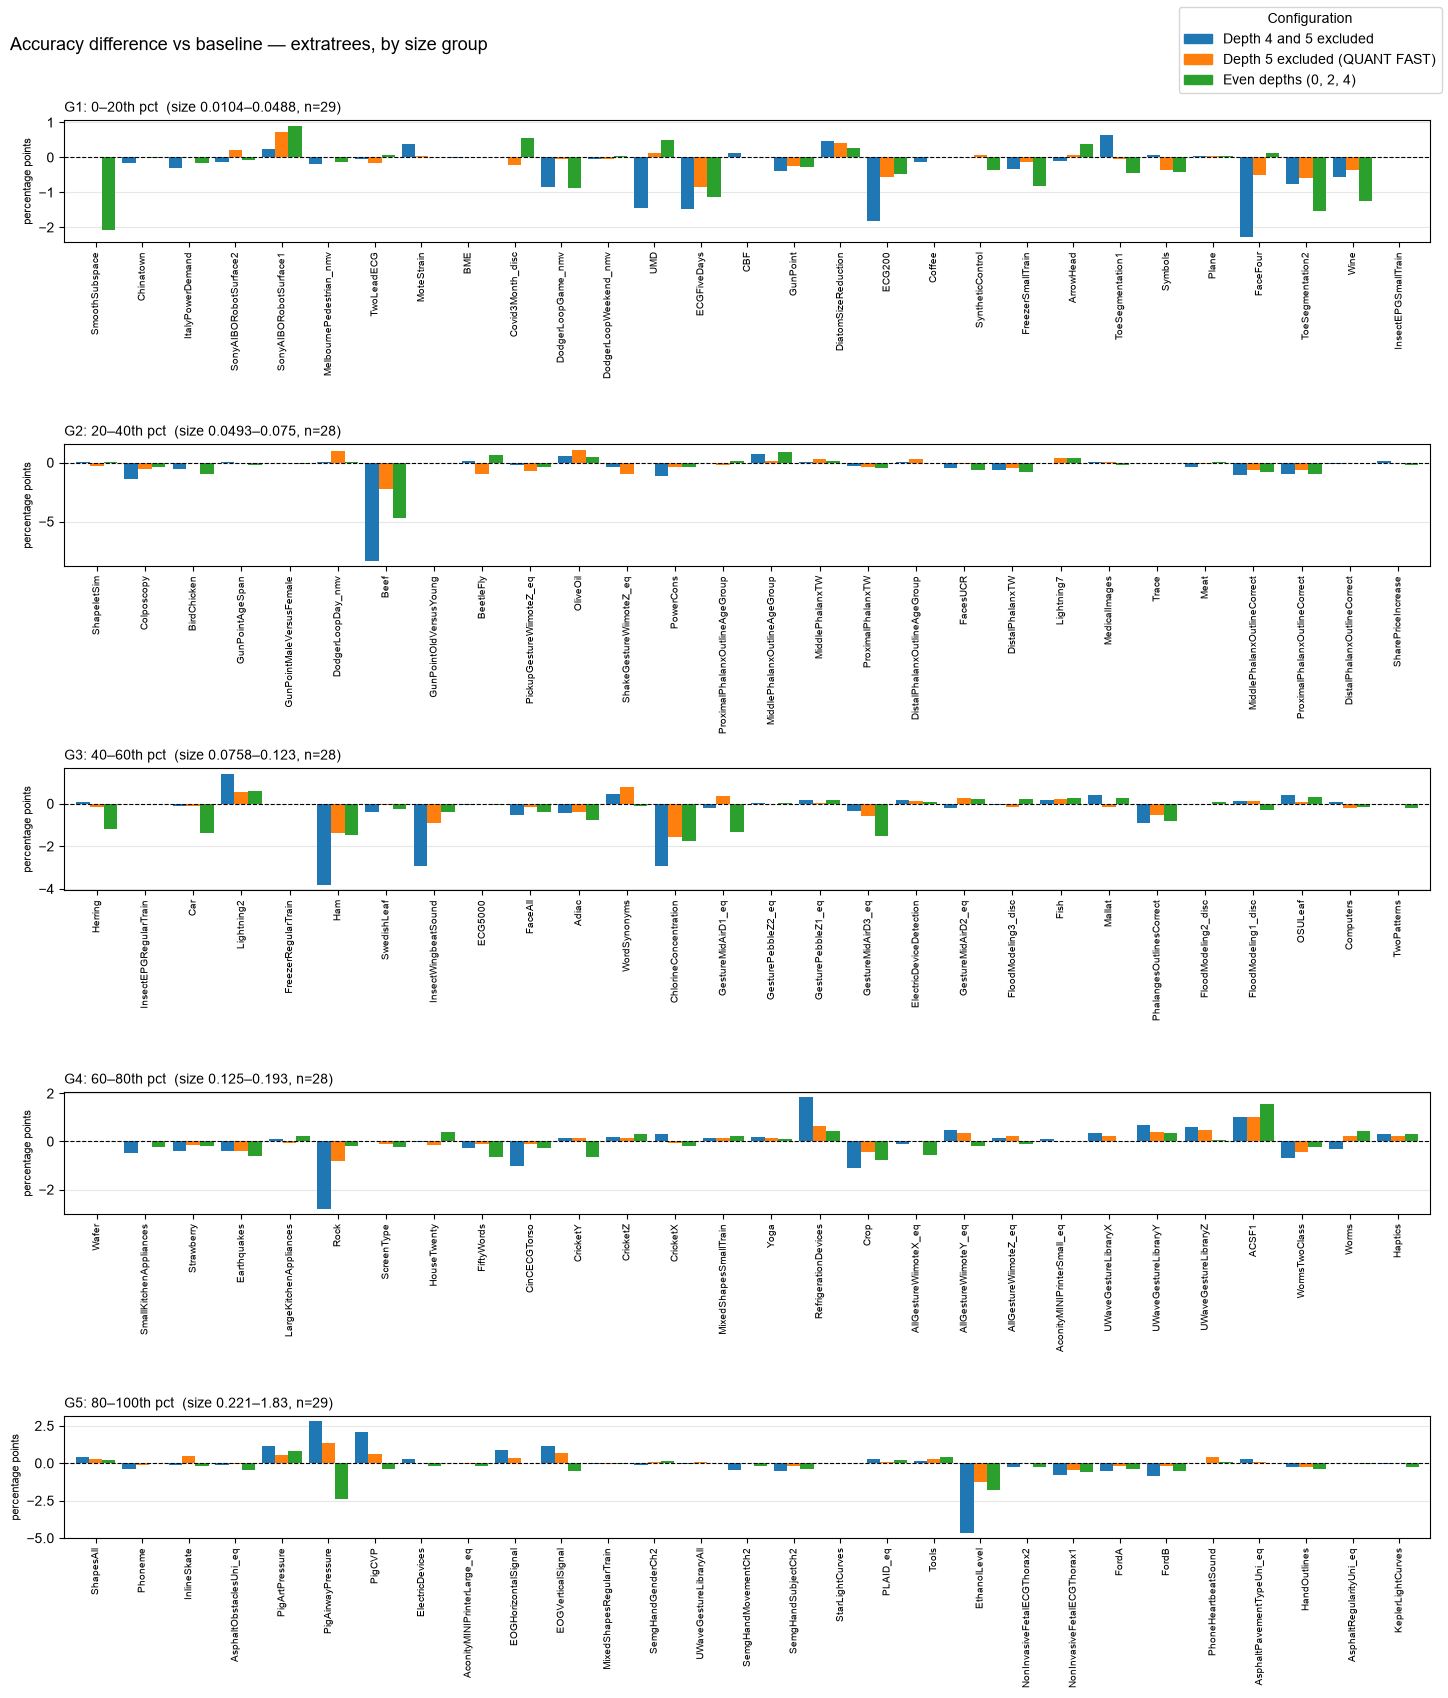

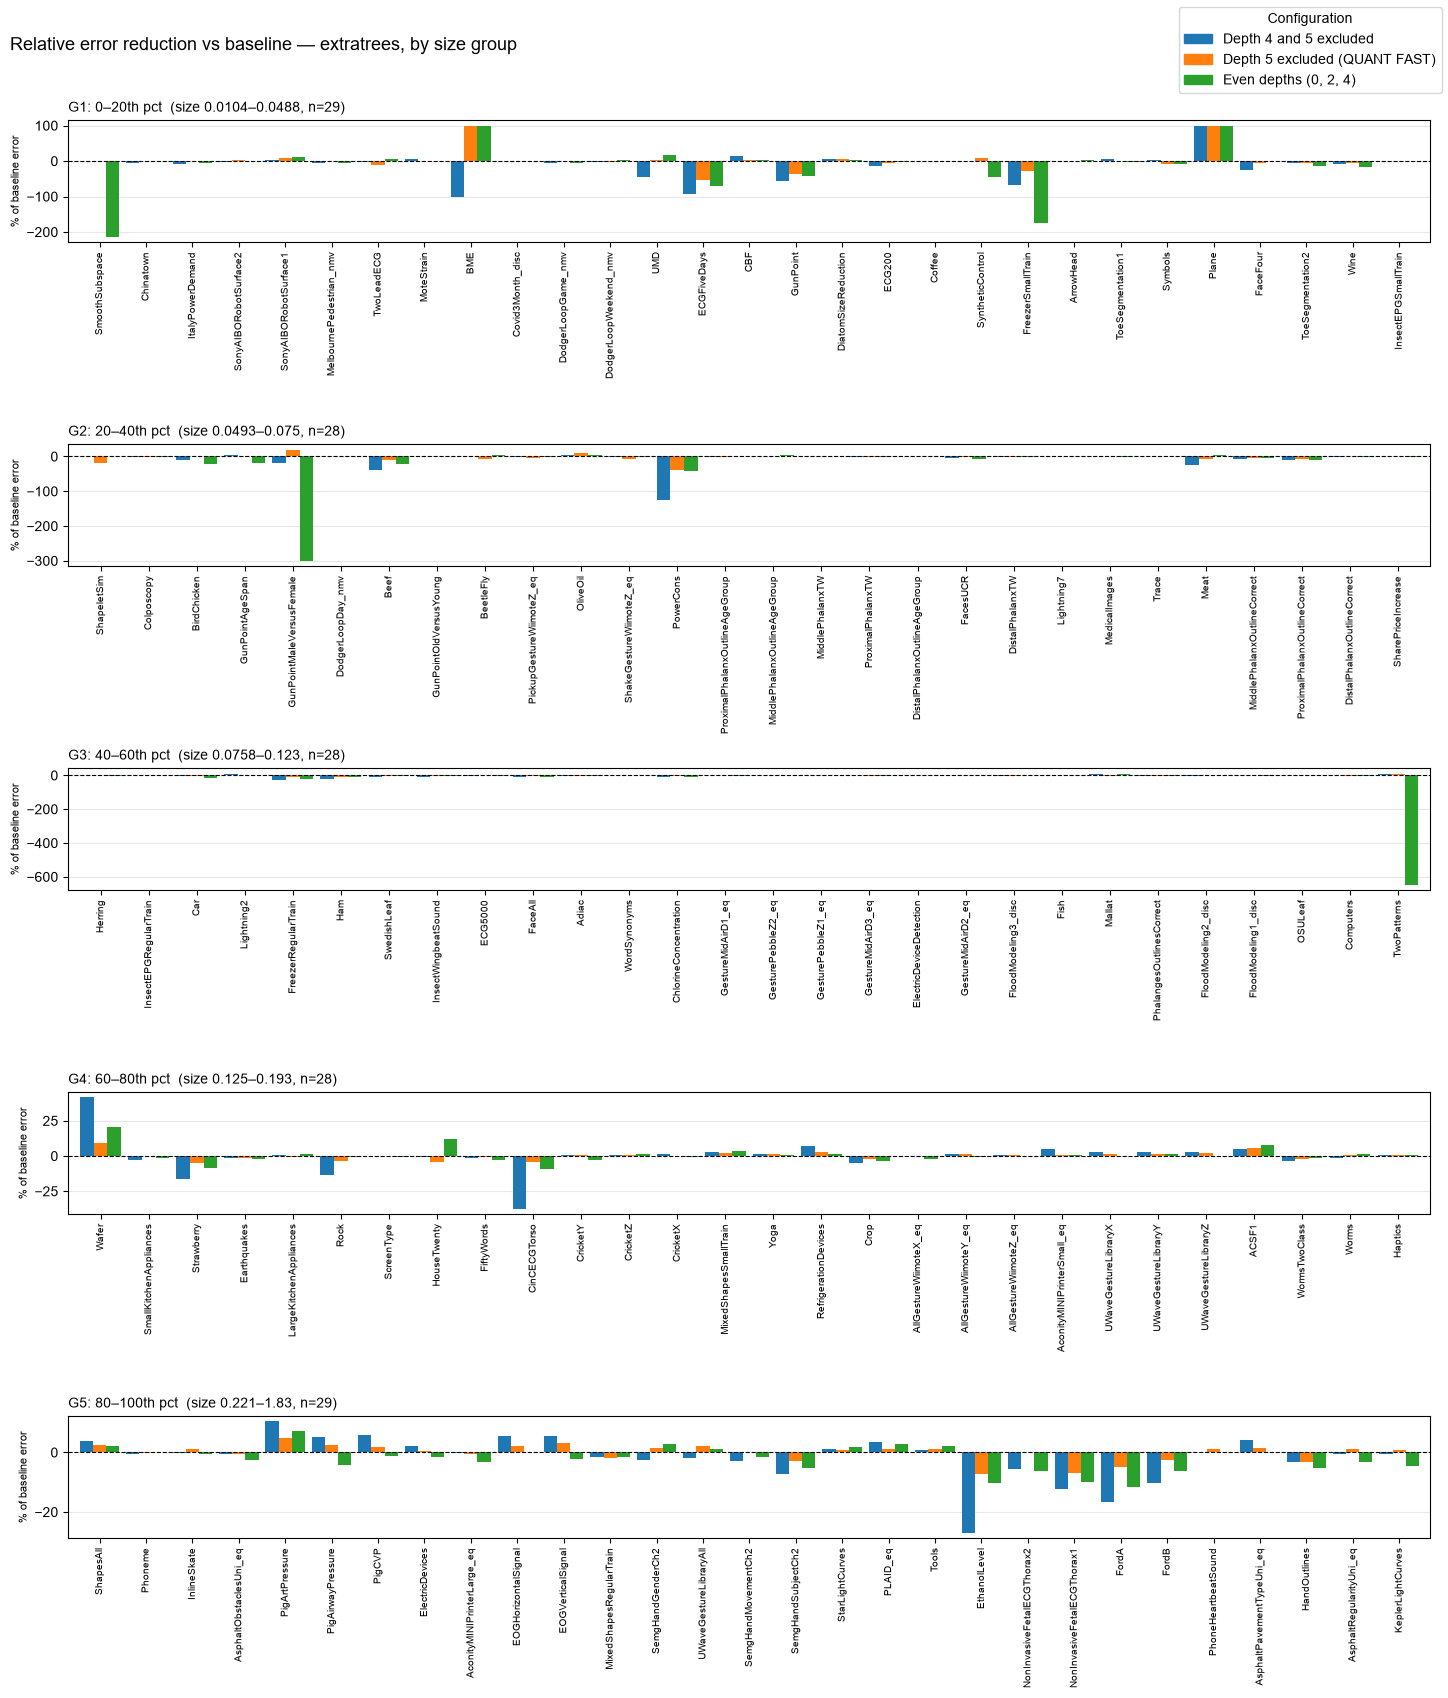

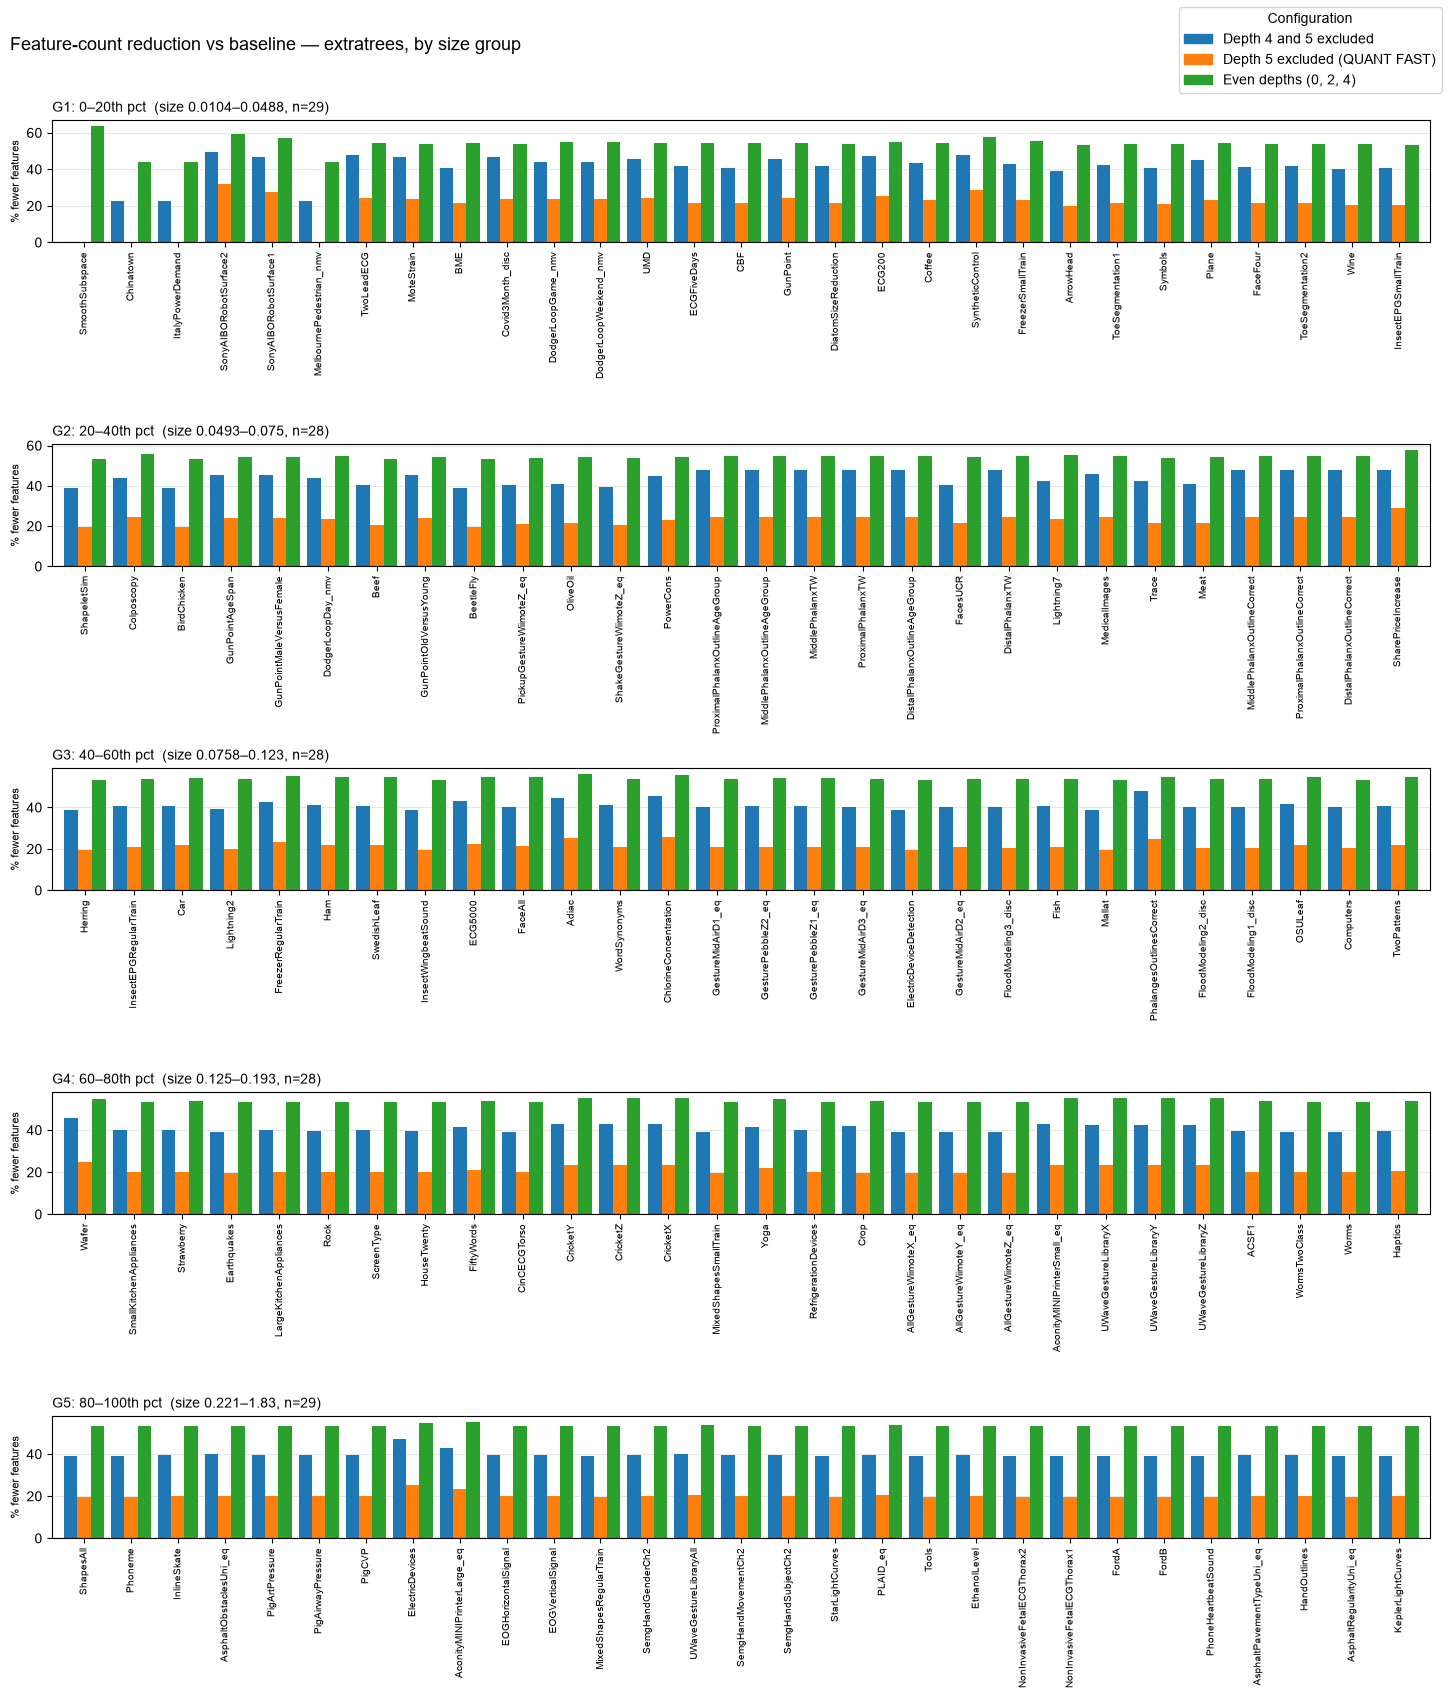

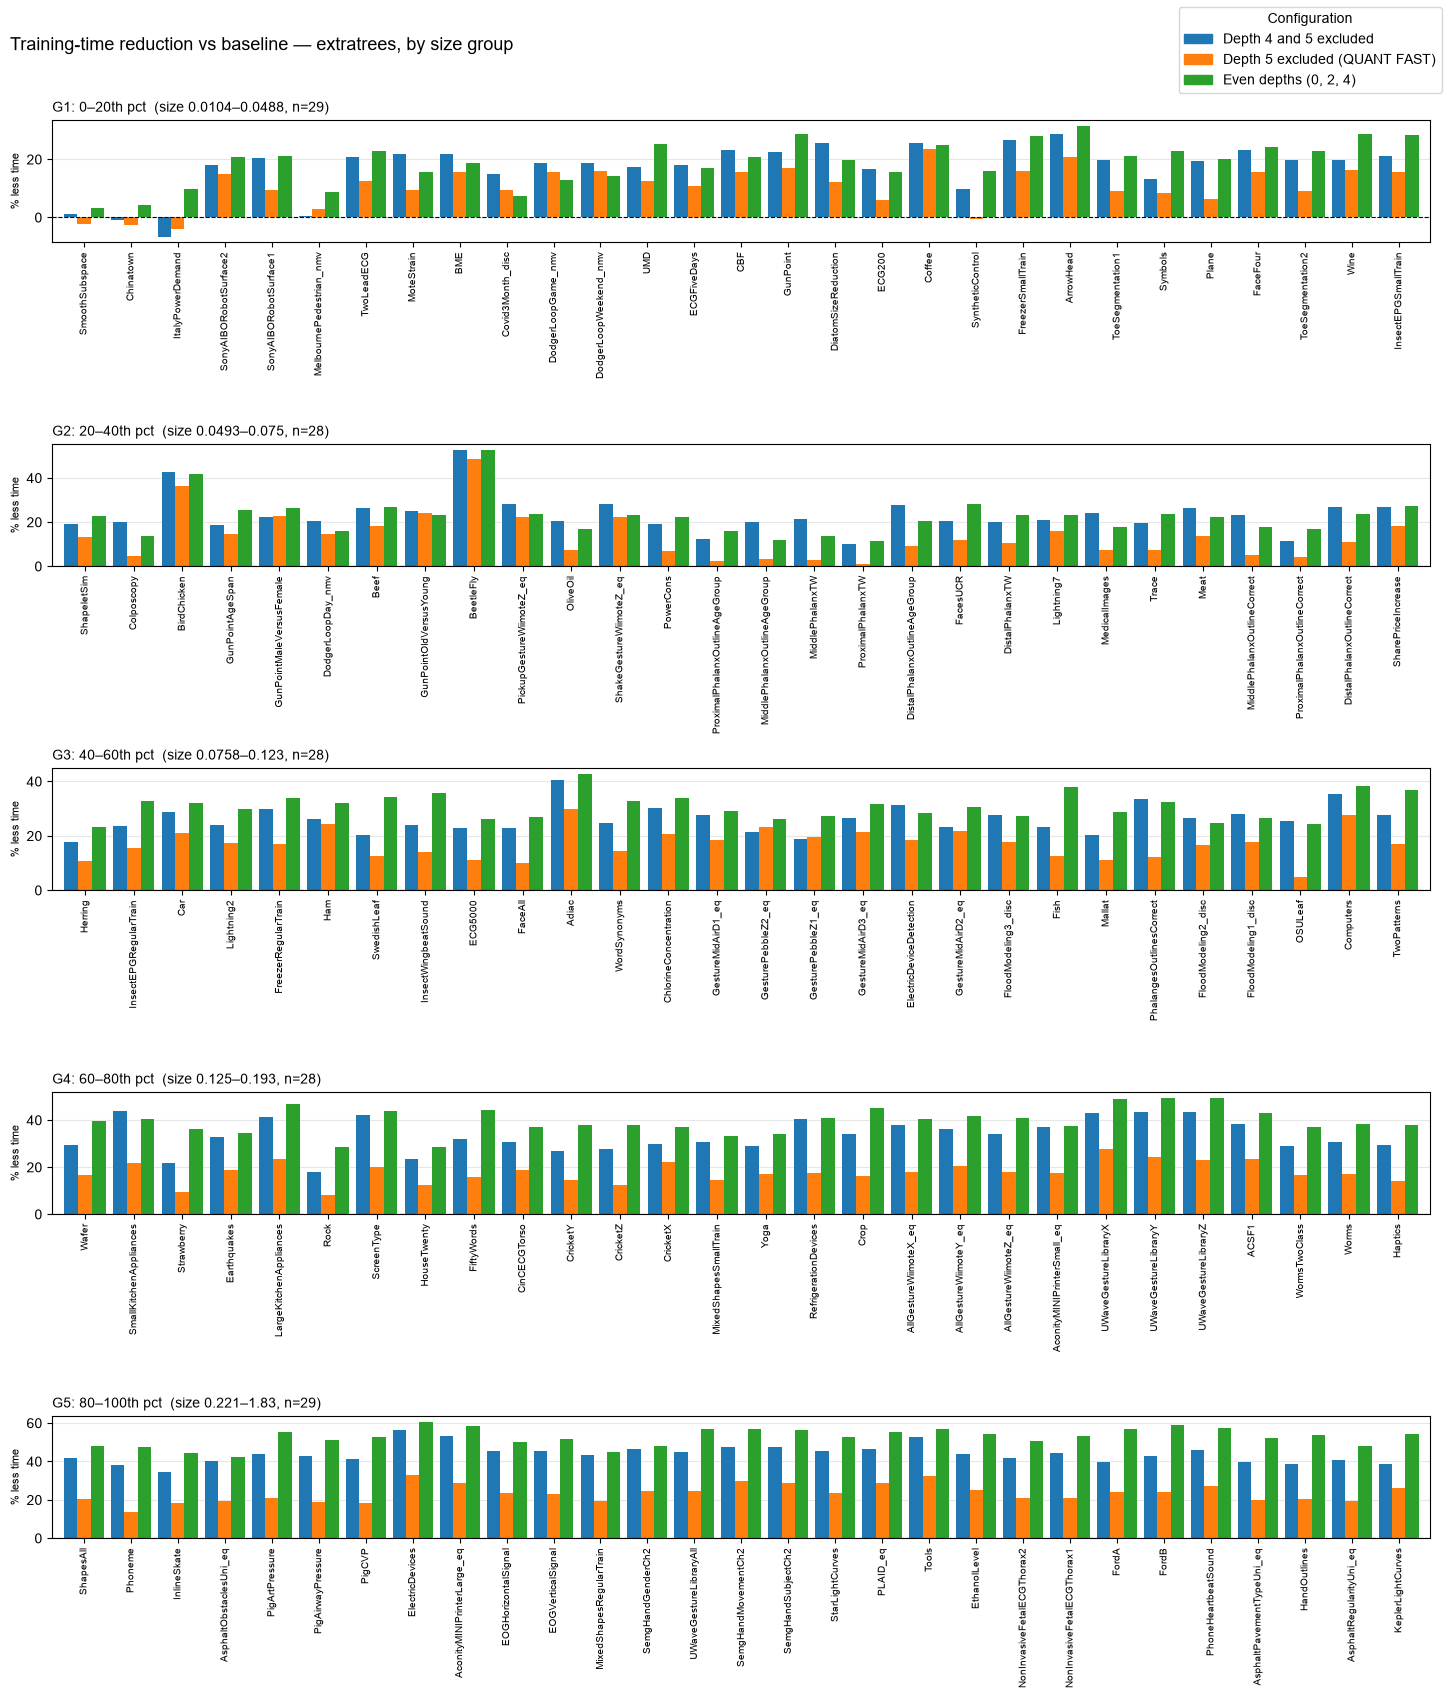

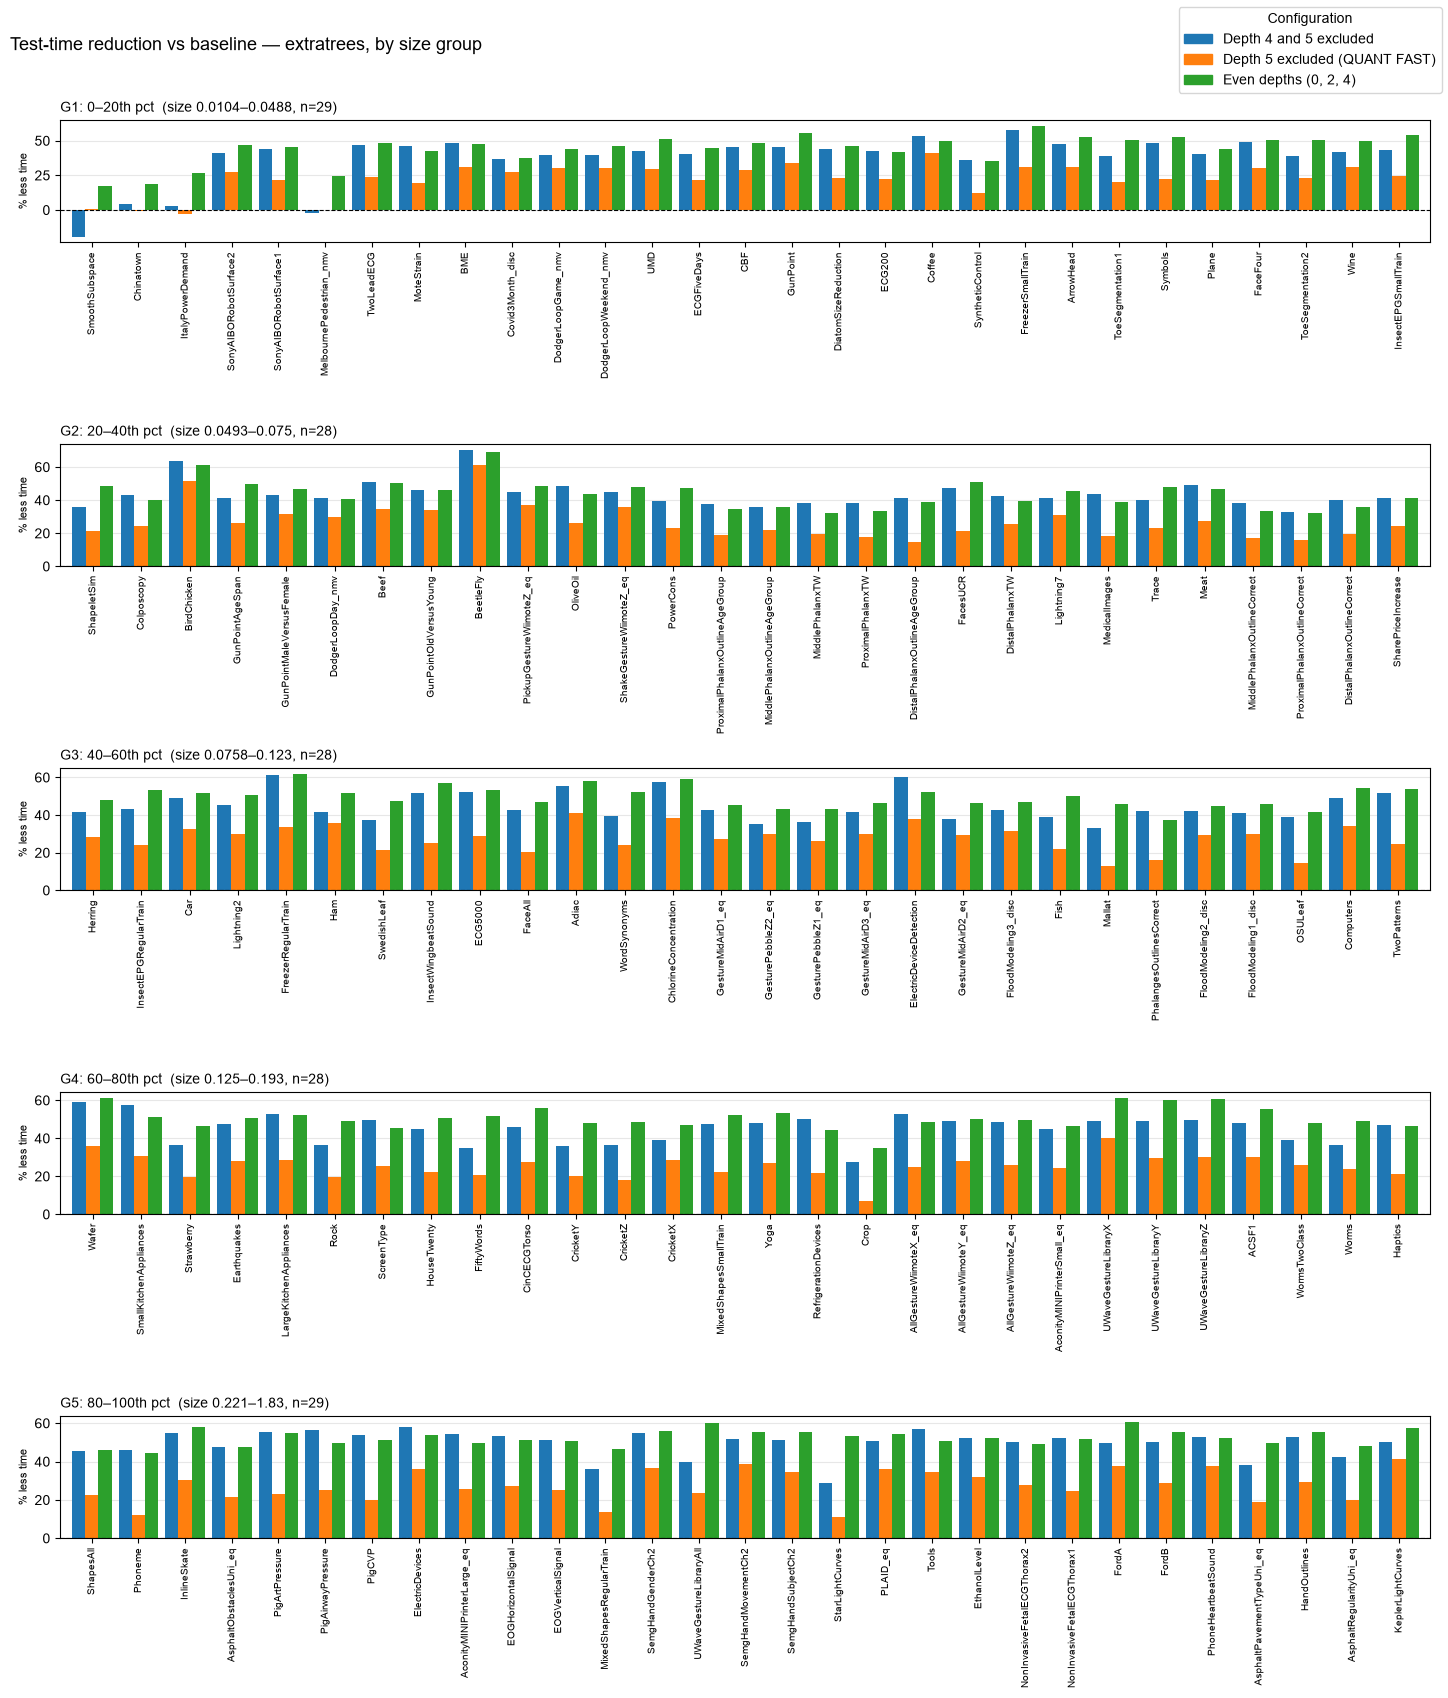

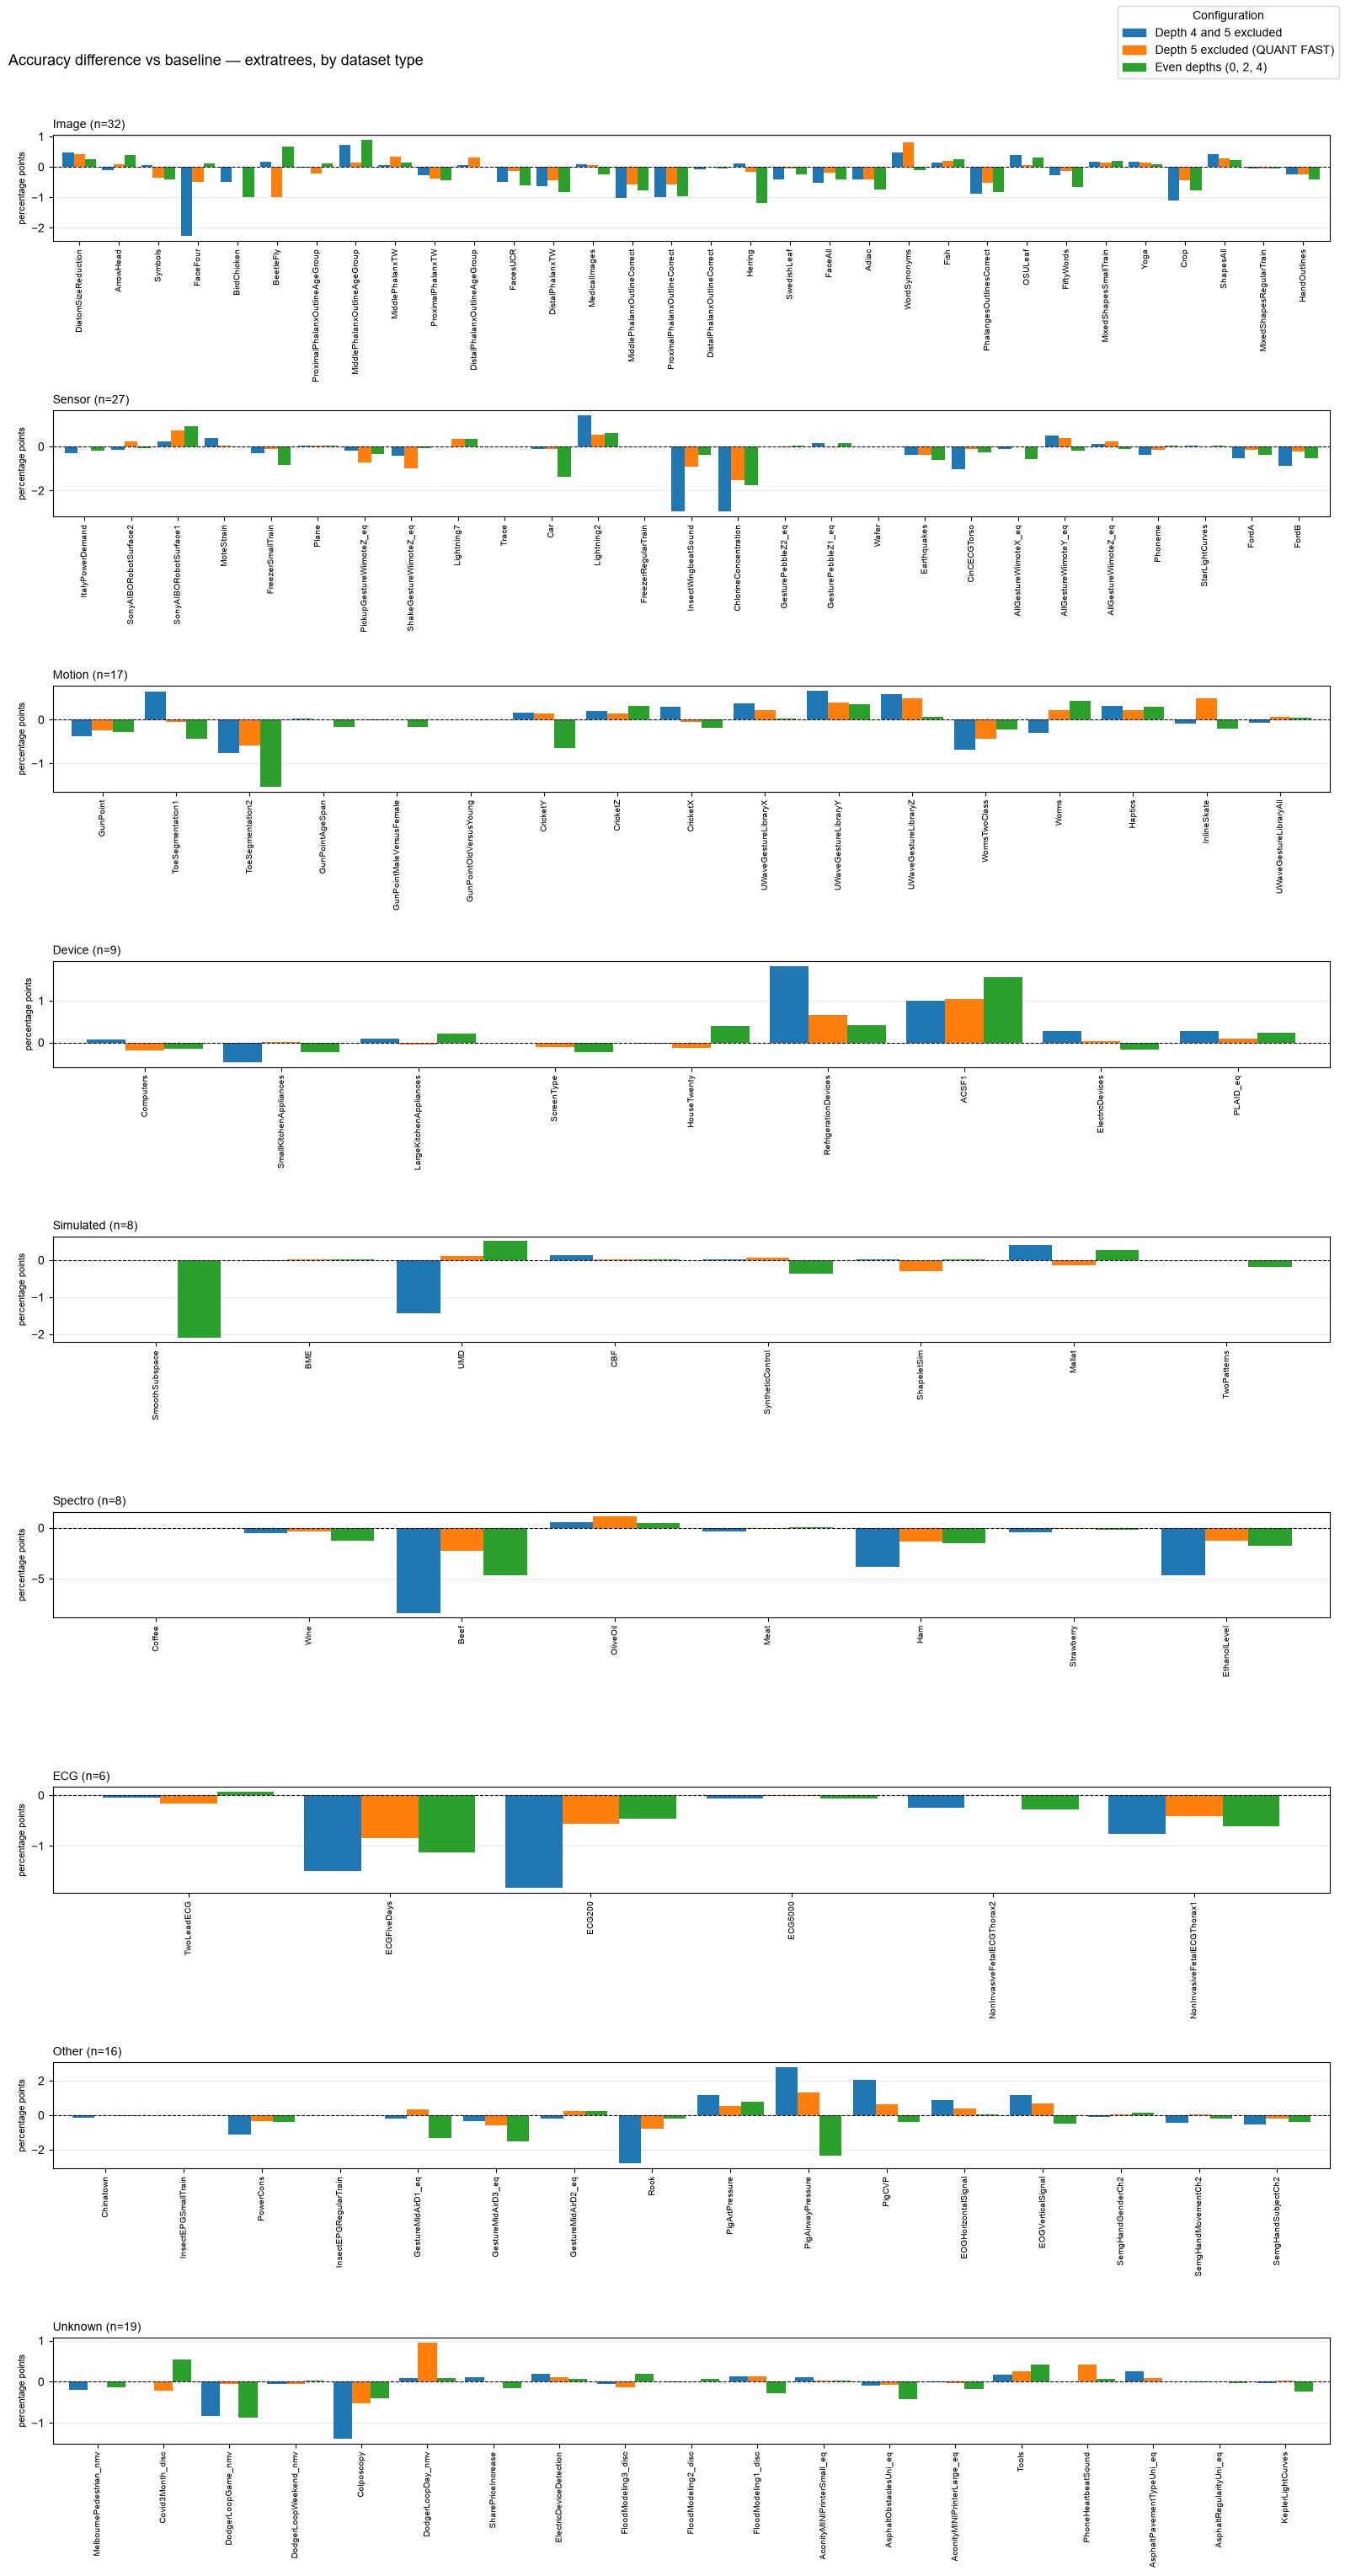

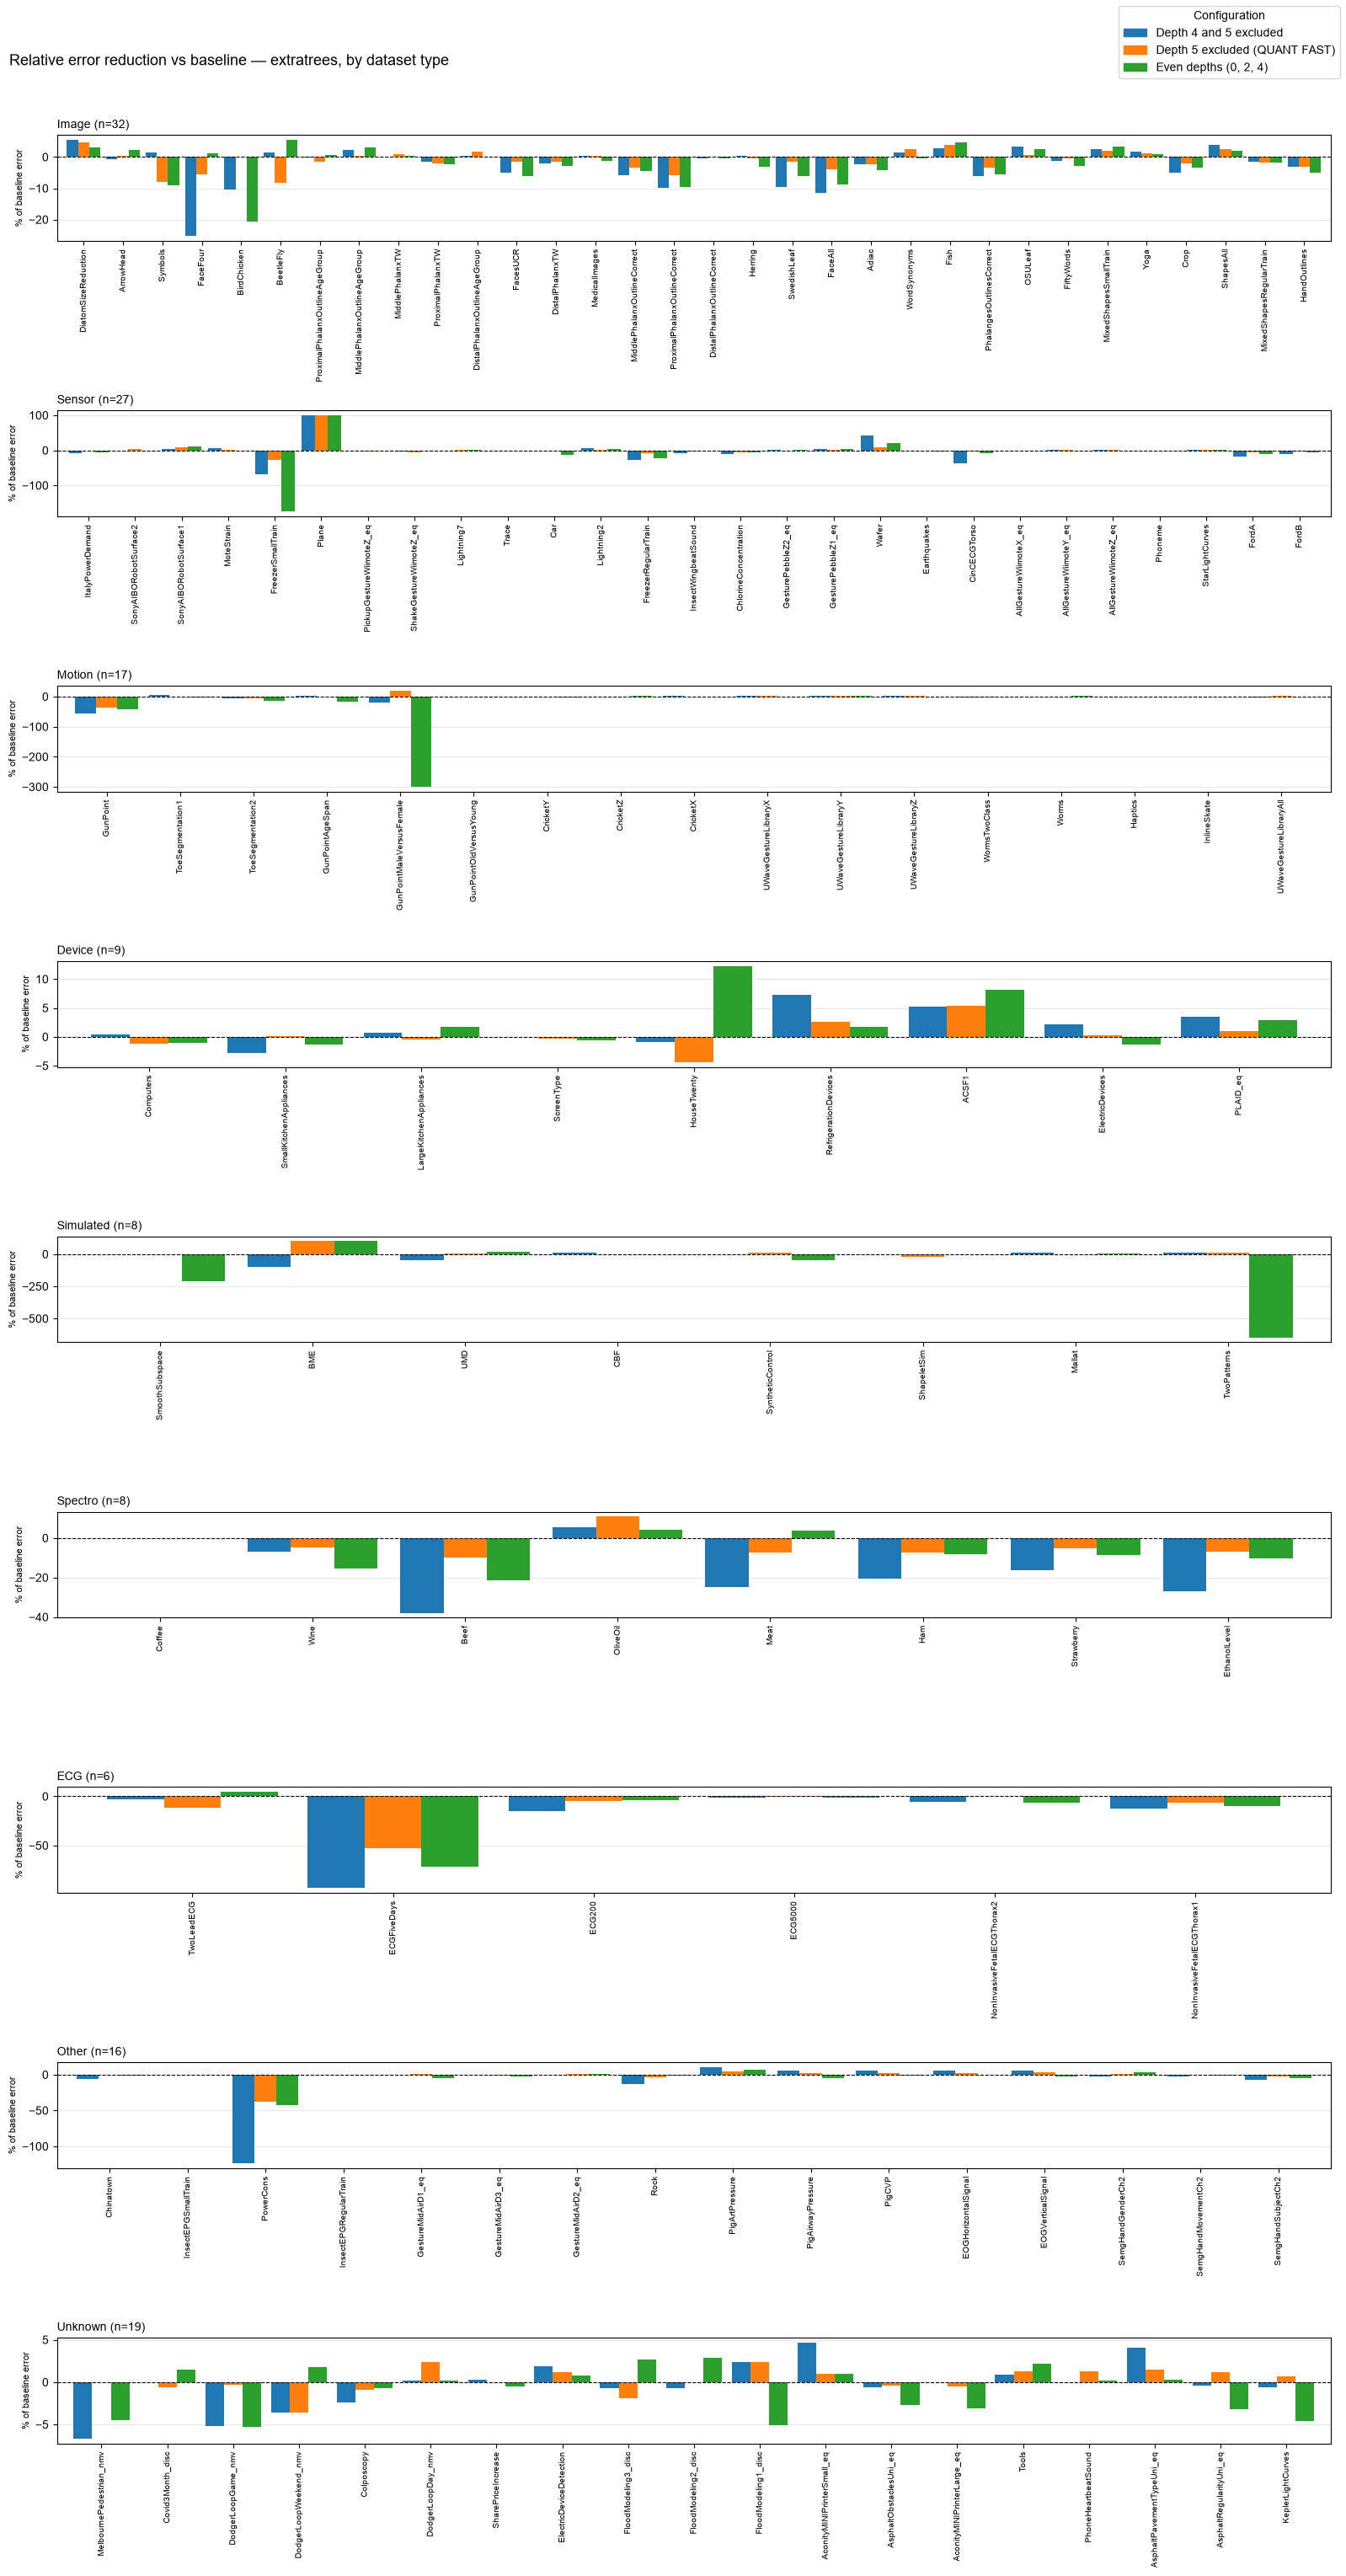

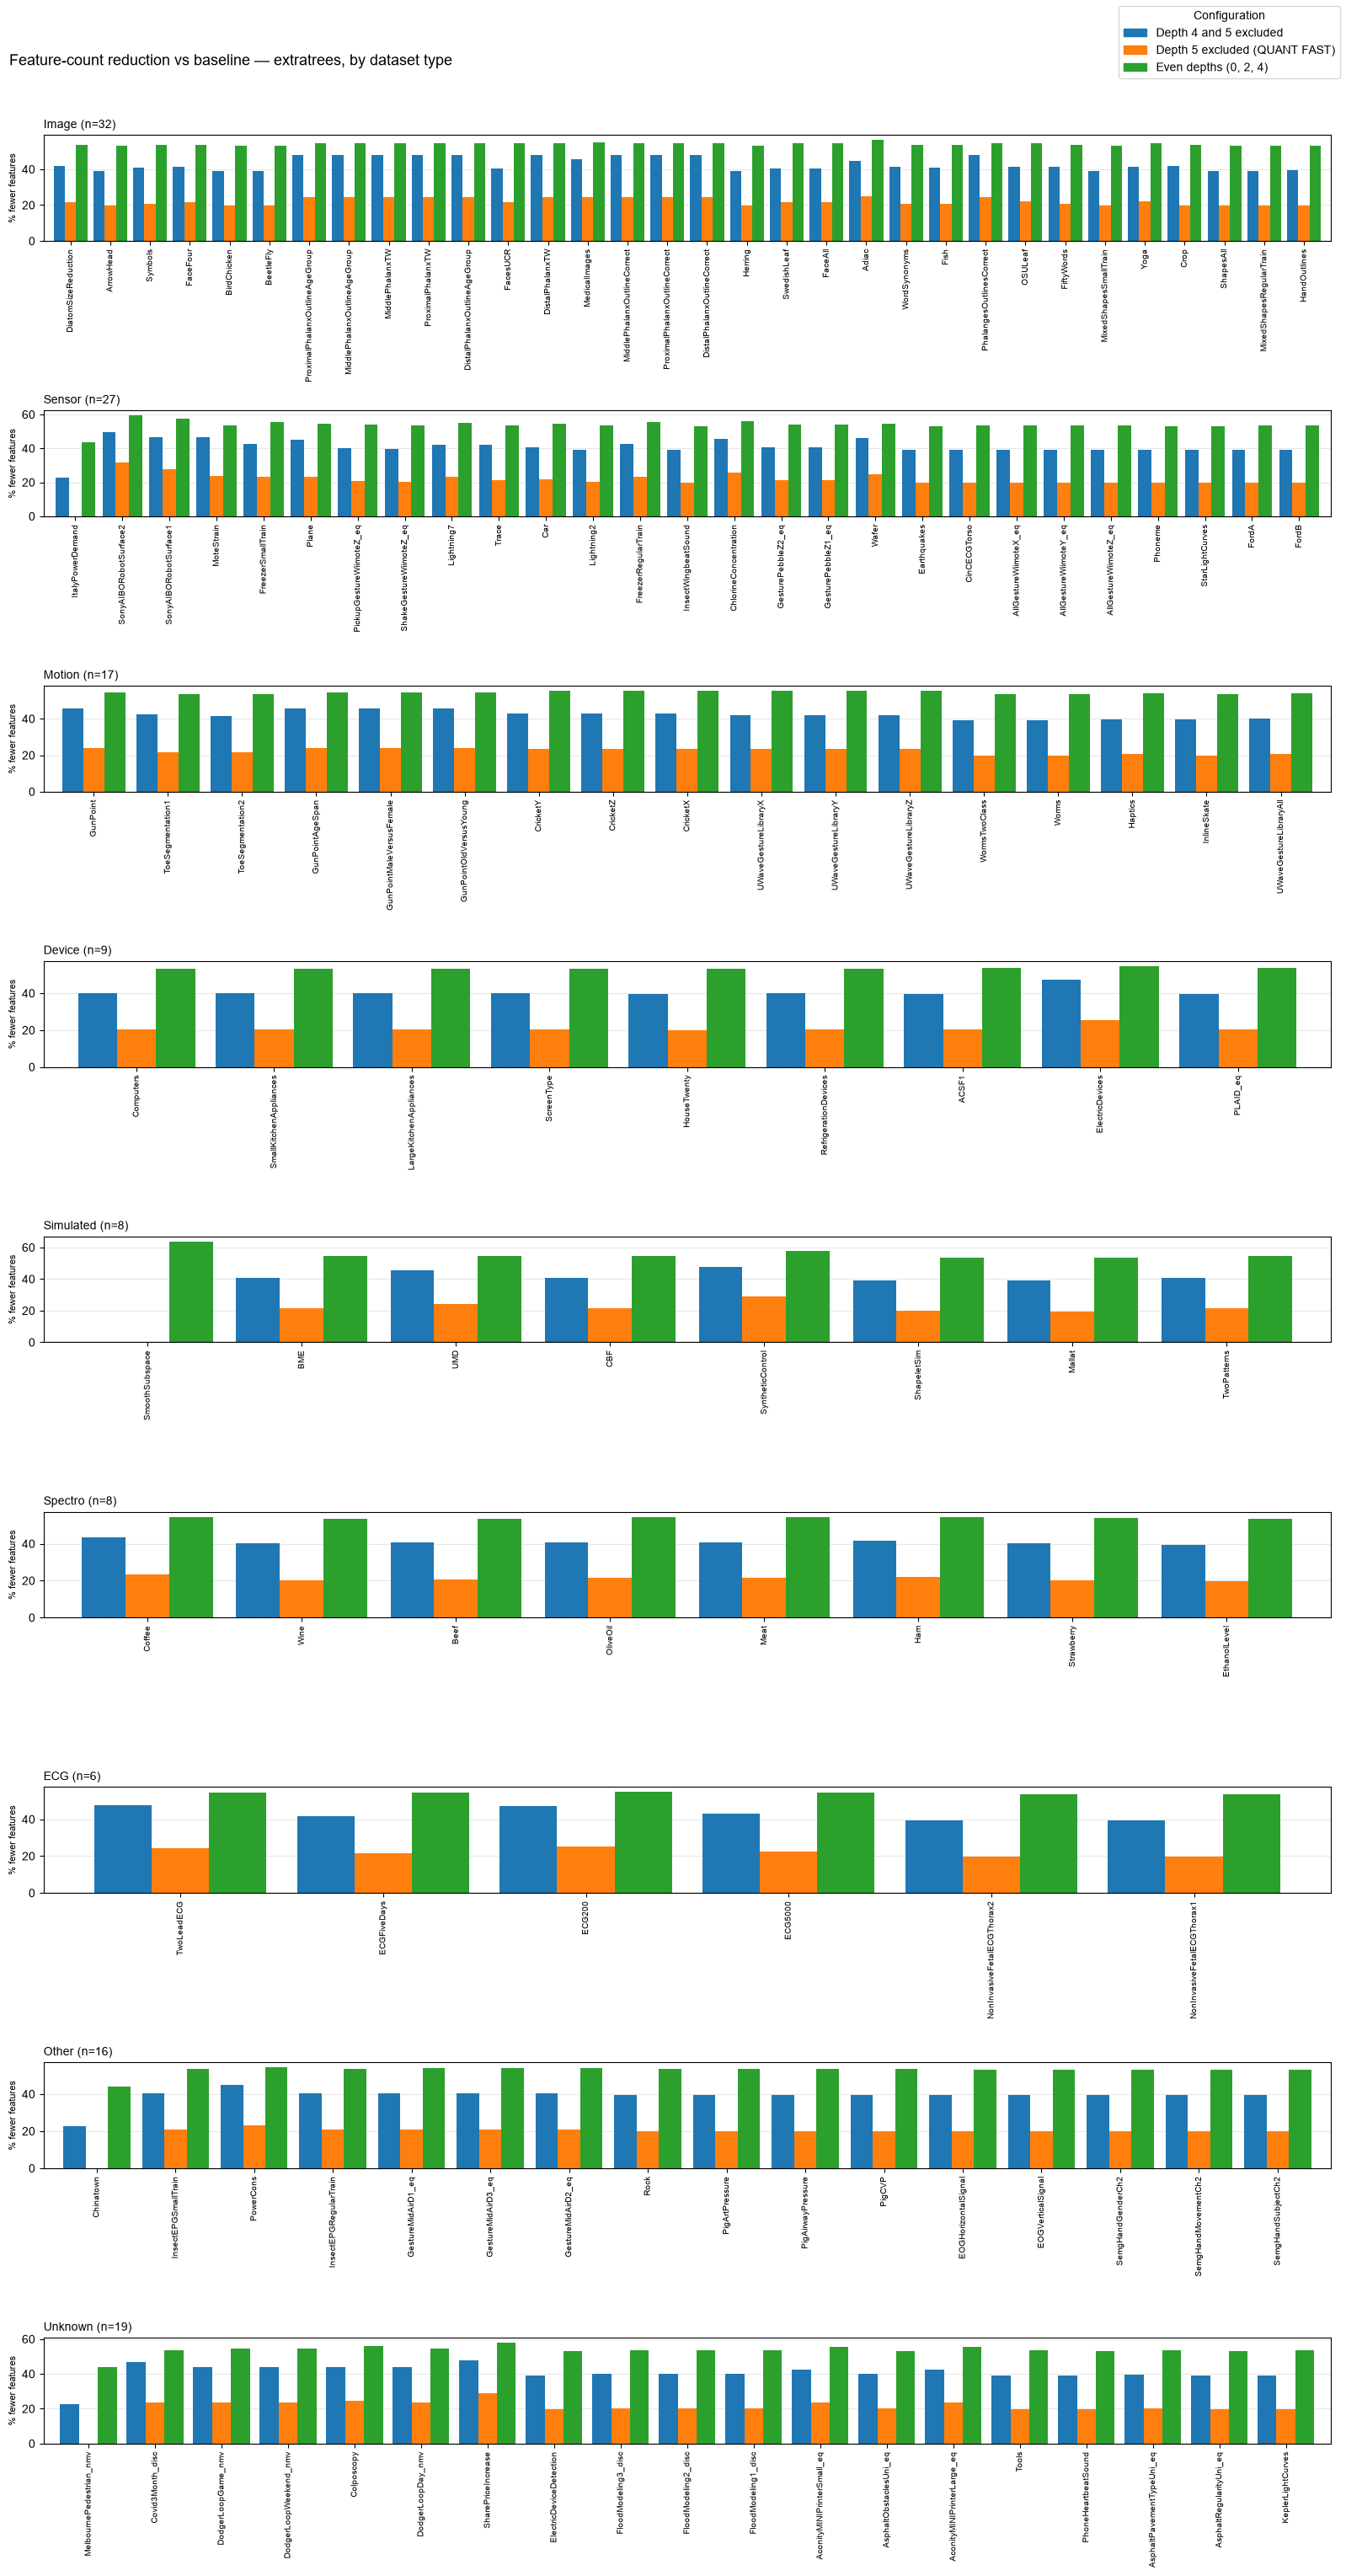

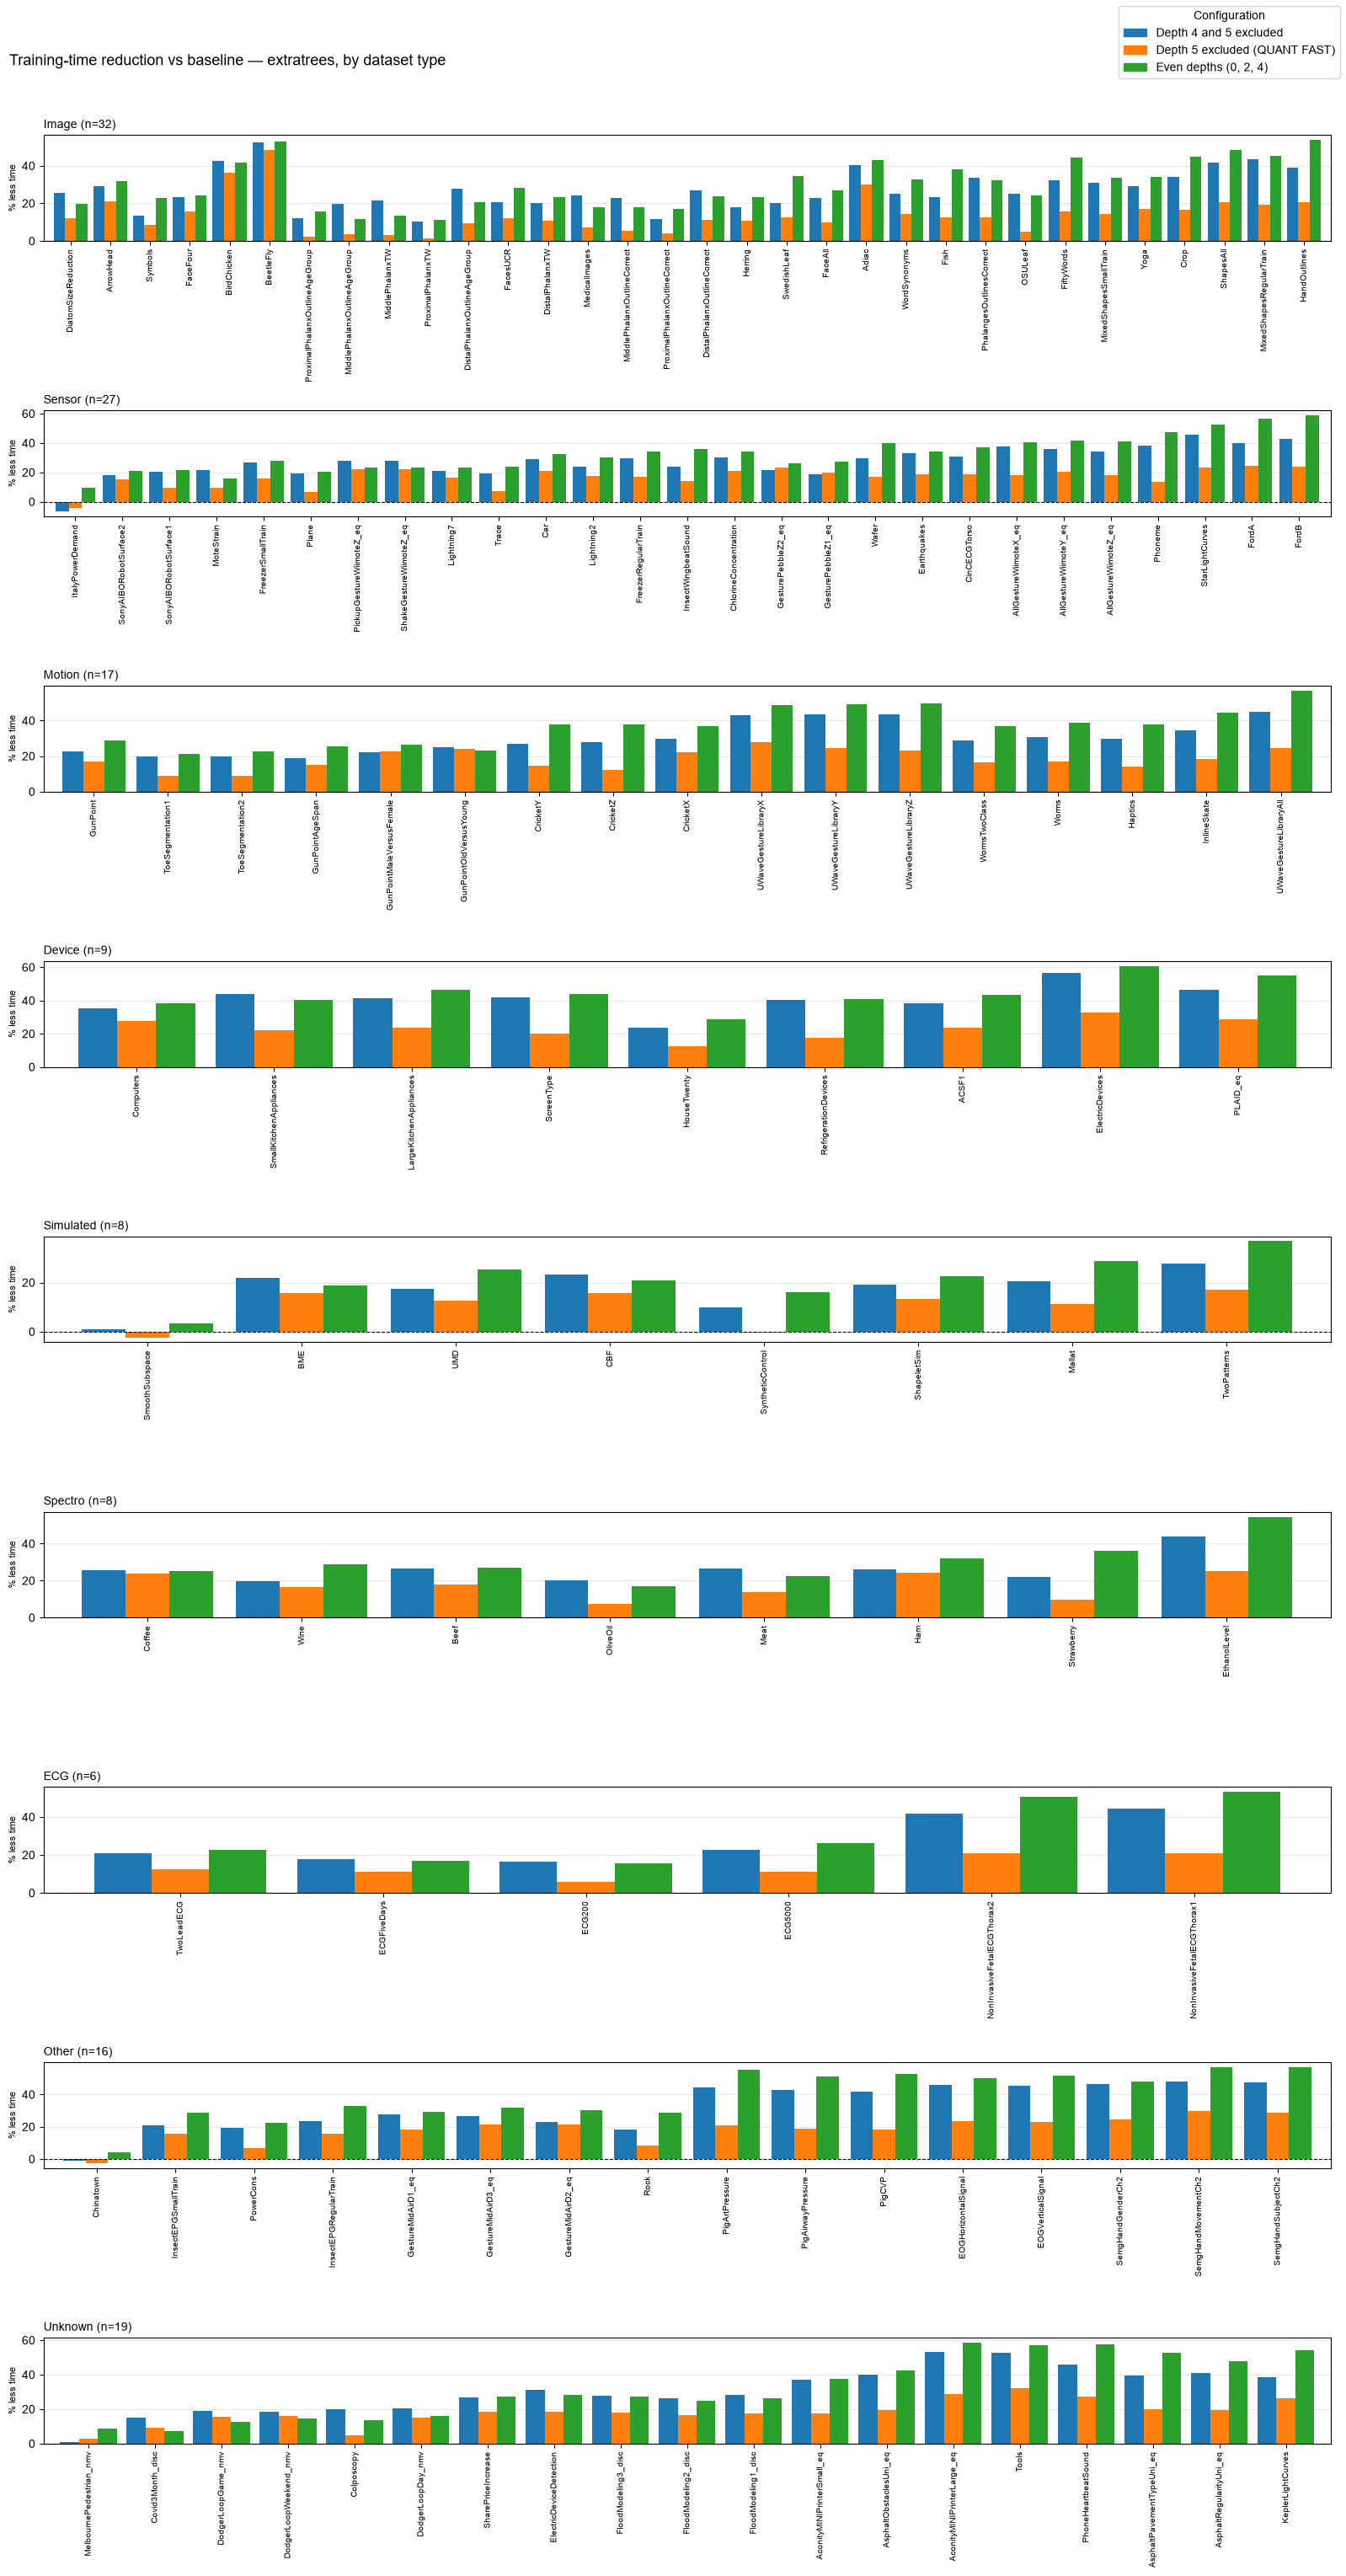

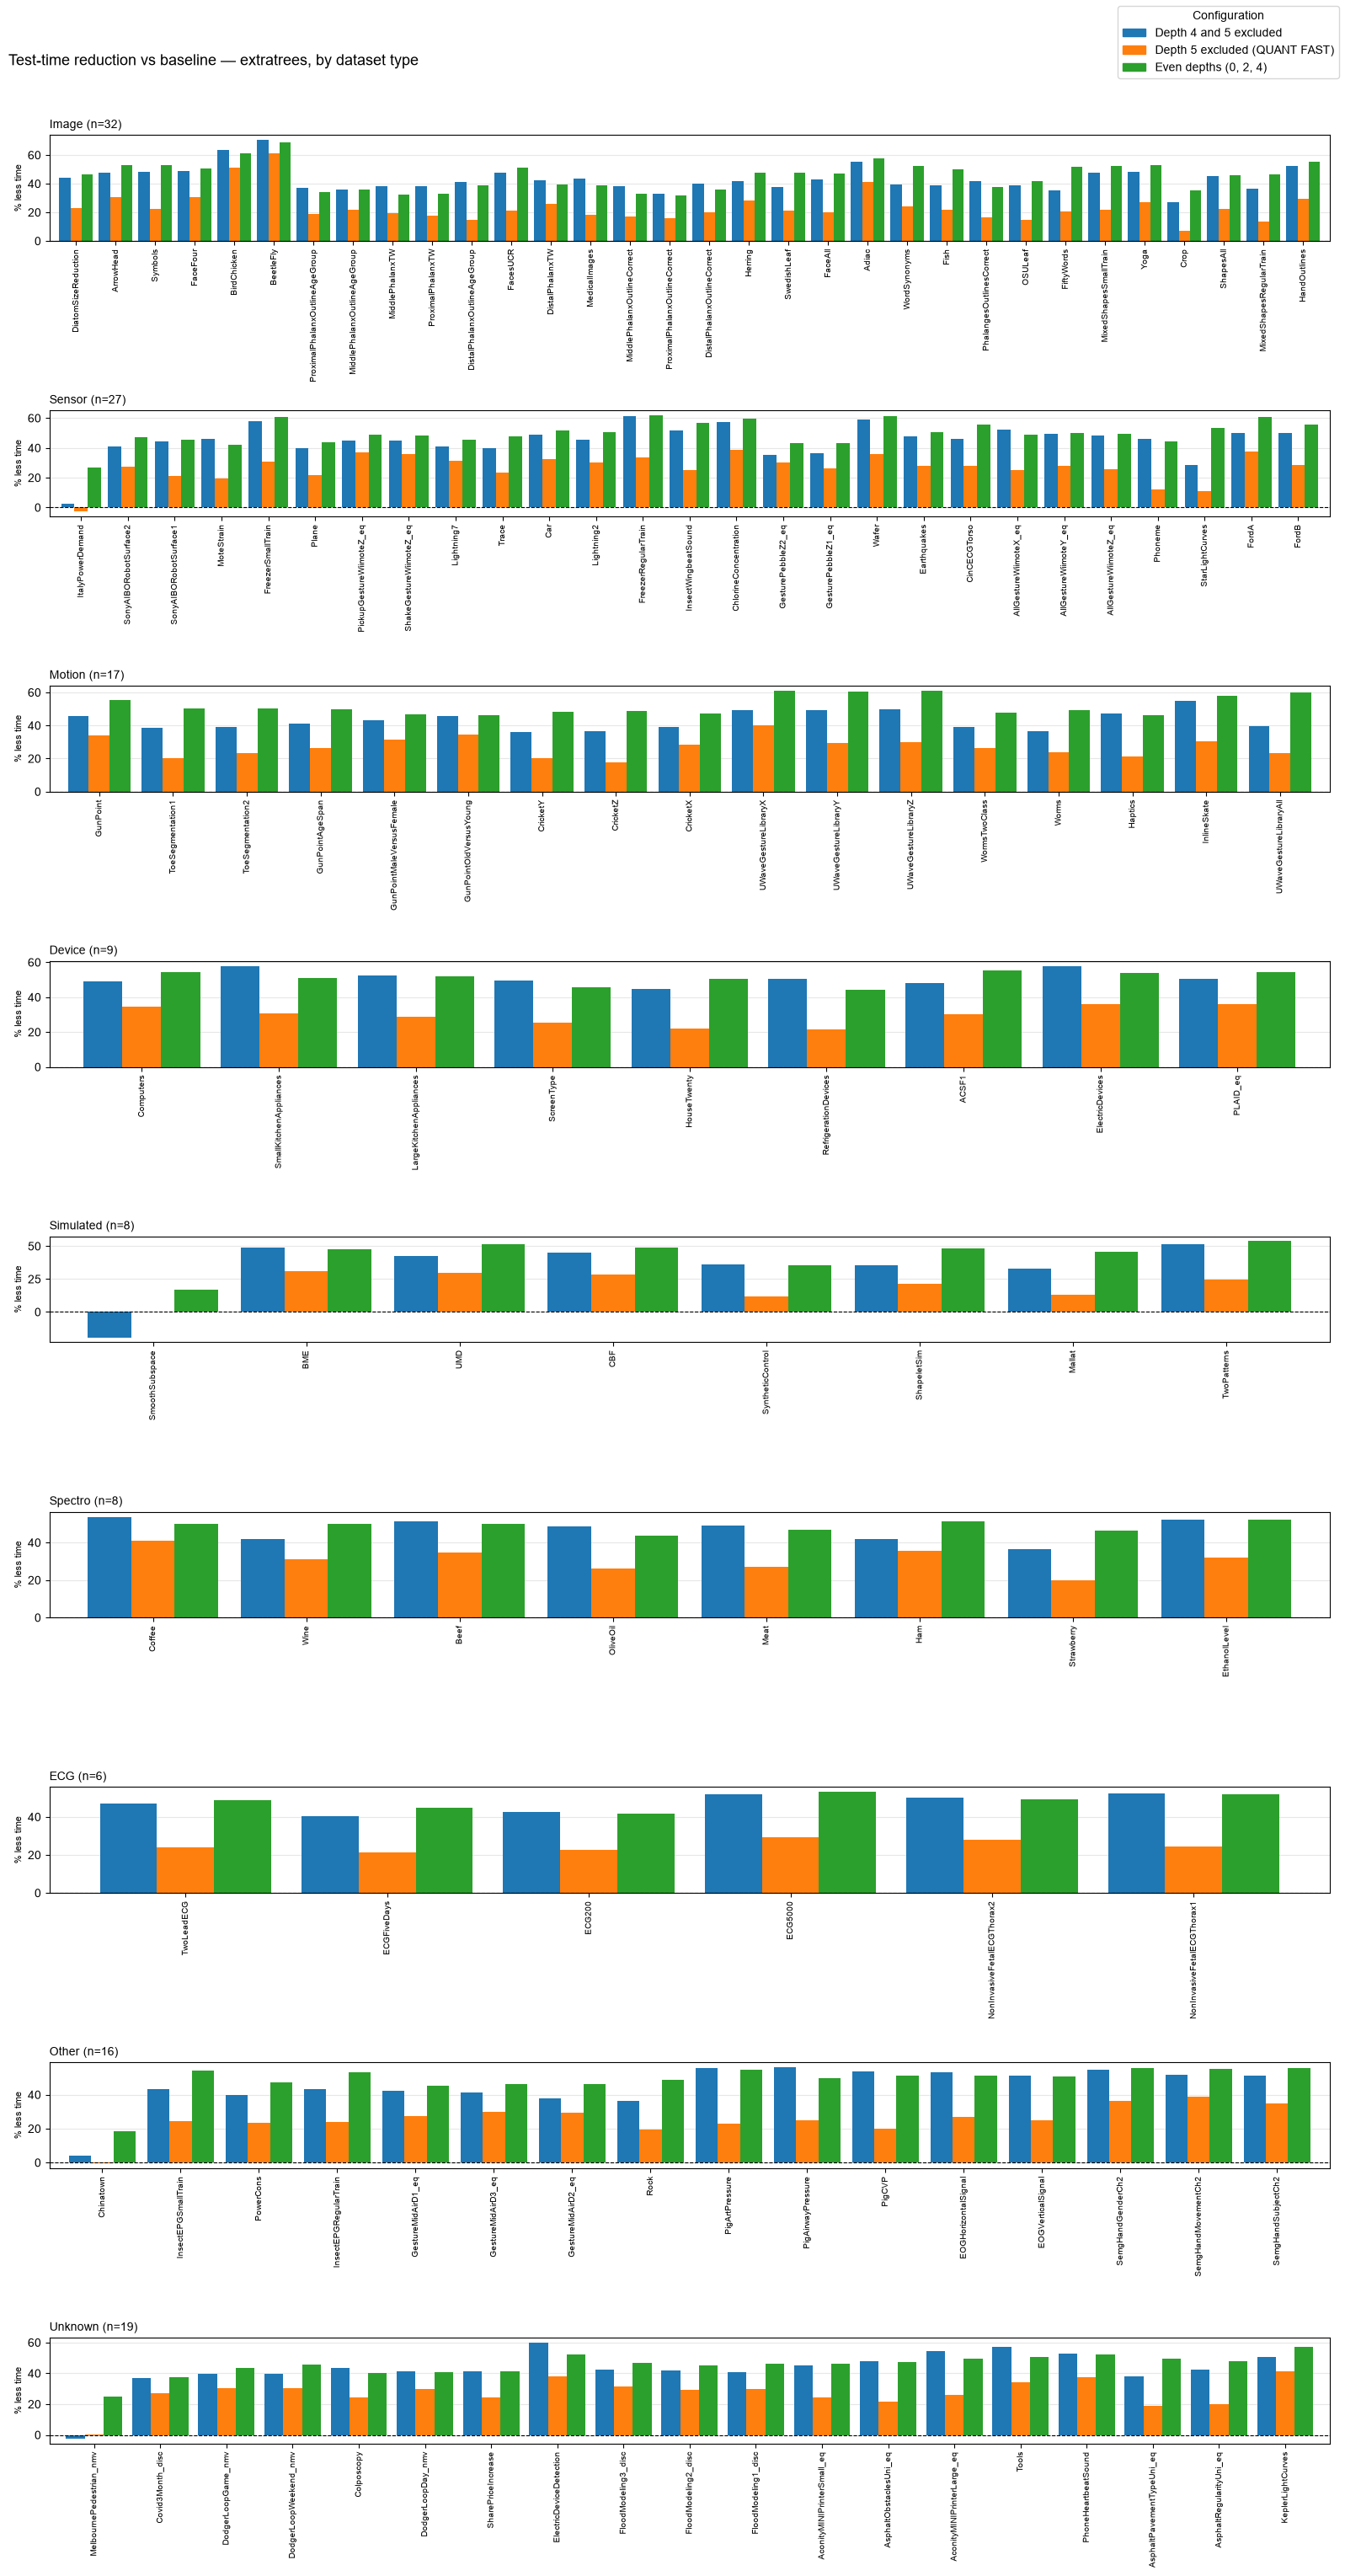

In [65]:
BAR_METRICS = {
    "acc_diff_pp": ("Accuracy difference vs baseline", "percentage points"),
    "error_reduction_pct": ("Relative error reduction vs baseline", "% of baseline error"),
    "feature_reduction_pct": ("Feature-count reduction vs baseline", "% fewer features"),
    "train_time_reduction_pct": ("Training-time reduction vs baseline", "% less time"),
    "test_time_reduction_pct": ("Test-time reduction vs baseline", "% less time"),
}

def plot_grouped_bars(metric, title, ylabel, grouping, col, order):
    for clf in classifiers:
        sub = cmp[cmp["classifier"] == clf]
        present = [name for name in order if (sub[col] == name).any()]
        if not present:
            continue
        widest = max((sub[col] == name).sum() // len(COMPARE_CONFIGS) for name in present)
        fig, axes = plt.subplots(len(present), 1, figsize=(max(14, 0.5 * widest), 3.4 * len(present)), squeeze=False)
        for ax, group_name in zip(axes[:, 0], present):
            g = sub[sub[col] == group_name]
            wide = g.pivot(index="dataset", columns="configuration", values=metric)
            wide = wide.loc[dataset_size.reindex(wide.index).sort_values().index, COMPARE_CONFIGS]
            wide.plot.bar(ax=ax, width=0.85, legend=False, color=[CONFIG_COLORS[c] for c in COMPARE_CONFIGS])
            ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
            ax.set_title(group_name, loc="left", fontsize=10)
            ax.set_xlabel("")
            ax.set_ylabel(ylabel, fontsize=8)
            ax.tick_params(axis="x", labelsize=7, rotation=90)
            ax.grid(axis="y", alpha=0.3)
            ax.set_axisbelow(True)
        fig.legend(handles=[Patch(color=CONFIG_COLORS[c], label=c) for c in COMPARE_CONFIGS],
                   title="Configuration", loc="upper right")
        fig.suptitle(f"{title} — {clf}, by {grouping}", x=0.01, ha="left", fontsize=13)
        fig.tight_layout(rect=(0, 0, 1, 0.97))
        plt.show()

for grouping, (col, order) in GROUPINGS.items():
    for metric, (title, ylabel) in BAR_METRICS.items():
        plot_grouped_bars(metric, title, ylabel, grouping, col, order)

## 9. Statistical significance

### 9a. Critical difference diagrams (across datasets)

Uses the Friedman test followed by Wilcoxon-Holm pairwise tests on the **per-dataset mean accuracies** (Demšar 2006; [hfawaz/cd-diagram](https://github.com/hfawaz/cd-diagram)). Methods joined by a thick bar are **not** significantly different. The first cell draws one diagram per classifier and per experiment group in `EXPERIMENT_GROUPS` (the baseline is always included); the second draws one per dataset-size group and one per dataset type.

Requires `cd_diagram.py`: the repo's `main.py`, renamed and with four small patches (no forced `agg` backend, no `exit()`, an output-file argument, and the example code guarded by `if __name__ == "__main__"`). The Friedman test needs at least 3 methods in a diagram, i.e. the baseline plus at least 2 configurations.

A significant rank difference means the configuration is *consistently* better or worse across datasets, not that the difference is large. Read it together with the accuracy differences in section 6. Groups contain only a few dozen datasets (or fewer), so "no significant difference" in a group mostly means low power, not evidence of equivalence.

<StringArray>
['Baseline (QUANT)', 'Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)']
Length: 4, dtype: str
Baseline (QUANT)                 44.0
Depth 4 and 5 excluded           37.0
Depth 5 excluded (QUANT FAST)    22.0
Even depths (0, 2, 4)            25.0
dtype: float64
Even depths (0, 2, 4)            2.757042
Depth 4 and 5 excluded           2.637324
Baseline (QUANT)                 2.359155
Depth 5 excluded (QUANT FAST)    2.246479
dtype: float64
('Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)', np.float64(4.433172742062486e-05), True)
('Baseline (QUANT)', 'Even depths (0, 2, 4)', np.float64(0.00020029814050472278), True)
('Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', np.float64(0.008508339320937254), True)
('Baseline (QUANT)', 'Depth 4 and 5 excluded', np.float64(0.03118906931160926), False)
('Baseline (QUANT)', 'Depth 5 excluded (QUANT FAST)', np.float64(0.4204607115683523), False)
('Depth 4 and 5 excluded', 'Even depths (

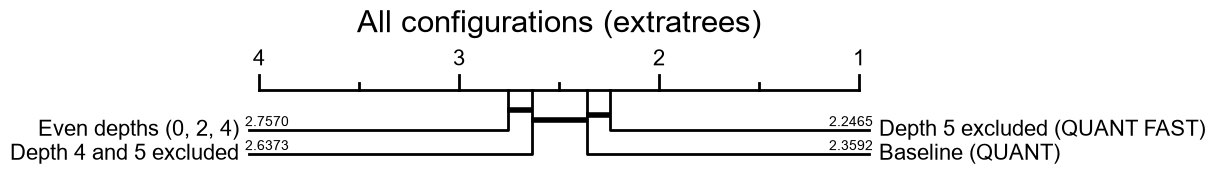

In [66]:
import re
import sys

CD_DIAGRAM_DIR = Path("..")      # folder that contains cd_diagram.py
sys.path.insert(0, str(CD_DIAGRAM_DIR.resolve()))
from cd_diagram import draw_cd_diagram

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
CD_ALPHA = 0.05

# One diagram per group below (the baseline is added to every group automatically).
EXPERIMENT_GROUPS = {
    "All configurations": COMPARE_CONFIGS,
    # "Depth removal": ["Depth 6 excluded", "Depth 5 and 6 excluded"],
    # "Interval selection": ["Even depths (0, 2, 4, 6)", "Alternating normal/shift"],
}

for clf in classifiers:
    for group_name, group_configs in EXPERIMENT_GROUPS.items():
        names = [BASELINE] + [c for c in group_configs if c != BASELINE]
        if len(names) < 3:
            print(f"Skipping '{group_name}' ({clf}): the Friedman test needs at least 3 methods, got {len(names)}.")
            continue
        slug = re.sub(r"\W+", "_", group_name)
        df_perf = (
            table[(table["classifier"] == clf) & table["configuration"].isin(names)]
            .rename(columns={"configuration": "classifier_name", "dataset": "dataset_name"})
            [["classifier_name", "dataset_name", "accuracy"]]
        )
        try:
            draw_cd_diagram(
                df_perf=df_perf, alpha=CD_ALPHA, title=f"{group_name} ({clf})", labels=True,
                filename=FIG_DIR / f"cd_{clf}_{slug}.png",
            )
        except RuntimeError as err:          # Friedman test not significant
            print(f"No diagram for '{group_name}' ({clf}): {err}")

<StringArray>
['Baseline (QUANT)', 'Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)']
Length: 4, dtype: str
Baseline (QUANT)                 7.0
Depth 4 and 5 excluded           5.0
Depth 5 excluded (QUANT FAST)    2.0
Even depths (0, 2, 4)            7.0
dtype: float64
Depth 4 and 5 excluded           2.982759
Even depths (0, 2, 4)            2.603448
Baseline (QUANT)                 2.206897
Depth 5 excluded (QUANT FAST)    2.206897
dtype: float64
('Baseline (QUANT)', 'Depth 4 and 5 excluded', np.float64(0.023140931308743732), False)
('Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', np.float64(0.02372981589471628), False)
('Baseline (QUANT)', 'Even depths (0, 2, 4)', np.float64(0.12461292712125822), False)
('Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)', np.float64(0.12888507323288942), False)
('Baseline (QUANT)', 'Depth 5 excluded (QUANT FAST)', np.float64(0.24042985739709466), False)
('Depth 4 and 5 excluded', 'Even depths (0, 2,

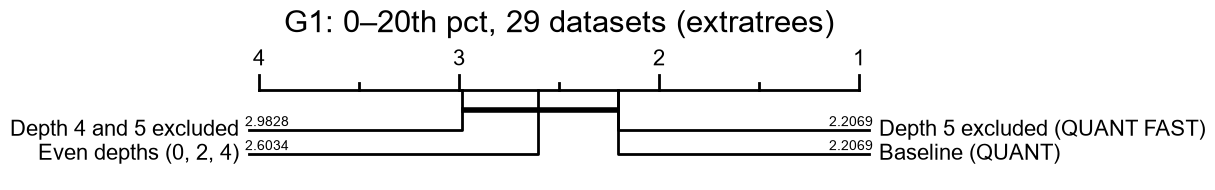

<StringArray>
['Baseline (QUANT)', 'Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)']
Length: 4, dtype: str
Baseline (QUANT)                 10.0
Depth 4 and 5 excluded            4.0
Depth 5 excluded (QUANT FAST)     6.0
Even depths (0, 2, 4)             4.0
dtype: float64
Even depths (0, 2, 4)            2.732143
Depth 4 and 5 excluded           2.714286
Depth 5 excluded (QUANT FAST)    2.285714
Baseline (QUANT)                 2.267857
dtype: float64
('Baseline (QUANT)', 'Even depths (0, 2, 4)', np.float64(0.07375401375945774), False)
('Baseline (QUANT)', 'Depth 4 and 5 excluded', np.float64(0.08546881714101226), False)
('Baseline (QUANT)', 'Depth 5 excluded (QUANT FAST)', np.float64(0.15102986976892957), False)
('Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', np.float64(0.1512553626470848), False)
('Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)', np.float64(0.19389226062113463), False)
('Depth 4 and 5 excluded', 'Even depths (0, 

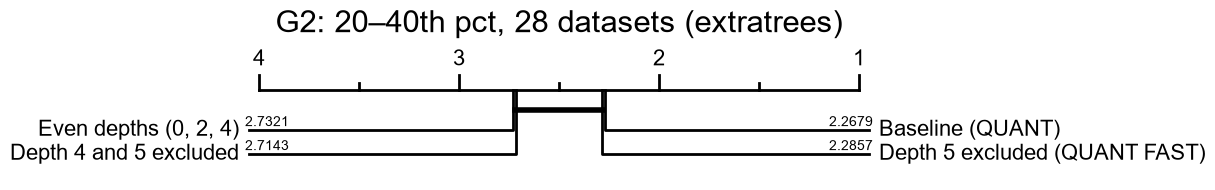

<StringArray>
['Baseline (QUANT)', 'Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)']
Length: 4, dtype: str
Baseline (QUANT)                 11.0
Depth 4 and 5 excluded            8.0
Depth 5 excluded (QUANT FAST)     4.0
Even depths (0, 2, 4)             4.0
dtype: float64
Even depths (0, 2, 4)            2.767857
Depth 4 and 5 excluded           2.589286
Depth 5 excluded (QUANT FAST)    2.428571
Baseline (QUANT)                 2.214286
dtype: float64
('Baseline (QUANT)', 'Even depths (0, 2, 4)', np.float64(0.03516153266236489), False)
('Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)', np.float64(0.0987313843820622), False)
('Baseline (QUANT)', 'Depth 5 excluded (QUANT FAST)', np.float64(0.20614971701884666), False)
('Baseline (QUANT)', 'Depth 4 and 5 excluded', np.float64(0.32187061637781267), False)
('Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', np.float64(0.34462041899087525), False)
('Depth 4 and 5 excluded', 'Even depths (0, 

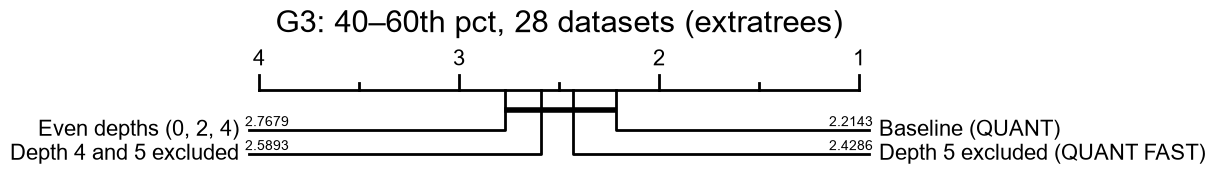

<StringArray>
['Baseline (QUANT)', 'Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)']
Length: 4, dtype: str
Baseline (QUANT)                  7.0
Depth 4 and 5 excluded           11.0
Depth 5 excluded (QUANT FAST)     3.0
Even depths (0, 2, 4)             6.0
dtype: float64
Even depths (0, 2, 4)            2.714286
Baseline (QUANT)                 2.696429
Depth 5 excluded (QUANT FAST)    2.321429
Depth 4 and 5 excluded           2.267857
dtype: float64
('Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)', np.float64(0.17183550757176747), False)
('Baseline (QUANT)', 'Depth 5 excluded (QUANT FAST)', np.float64(0.27407141774892807), False)
('Baseline (QUANT)', 'Even depths (0, 2, 4)', np.float64(0.6618045940995216), False)
('Depth 4 and 5 excluded', 'Even depths (0, 2, 4)', np.float64(0.7281656339764595), False)
('Baseline (QUANT)', 'Depth 4 and 5 excluded', np.float64(0.7759036854411466), False)
('Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FA

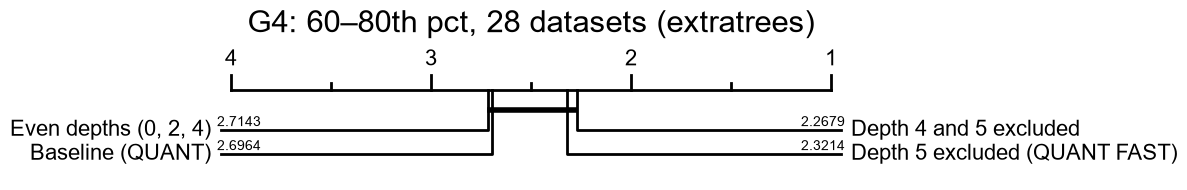

<StringArray>
['Baseline (QUANT)', 'Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)']
Length: 4, dtype: str
Baseline (QUANT)                 9.0
Depth 4 and 5 excluded           9.0
Depth 5 excluded (QUANT FAST)    7.0
Even depths (0, 2, 4)            4.0
dtype: float64
Even depths (0, 2, 4)            2.965517
Depth 4 and 5 excluded           2.620690
Baseline (QUANT)                 2.413793
Depth 5 excluded (QUANT FAST)    2.000000
dtype: float64
('Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)', np.float64(0.00033221766352653503), True)
('Baseline (QUANT)', 'Even depths (0, 2, 4)', np.float64(0.022908341139554977), False)
('Baseline (QUANT)', 'Depth 5 excluded (QUANT FAST)', np.float64(0.16216303035616875), False)
('Depth 4 and 5 excluded', 'Even depths (0, 2, 4)', np.float64(0.32500122487545013), False)
('Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', np.float64(0.44202057644724846), False)
('Baseline (QUANT)', 'Depth 4 and 5 exc

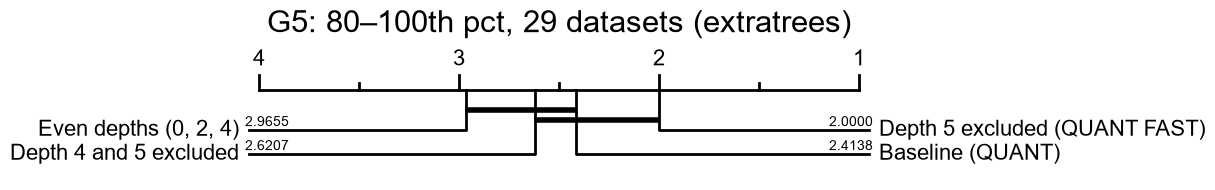

<StringArray>
['Baseline (QUANT)', 'Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)']
Length: 4, dtype: str
Baseline (QUANT)                 13.0
Depth 4 and 5 excluded            7.0
Depth 5 excluded (QUANT FAST)     4.0
Even depths (0, 2, 4)             7.0
dtype: float64
Even depths (0, 2, 4)            2.843750
Depth 4 and 5 excluded           2.625000
Baseline (QUANT)                 2.265625
Depth 5 excluded (QUANT FAST)    2.265625
dtype: float64
('Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)', np.float64(0.03411991102620959), False)
('Baseline (QUANT)', 'Even depths (0, 2, 4)', np.float64(0.03942684410139918), False)
('Baseline (QUANT)', 'Depth 5 excluded (QUANT FAST)', np.float64(0.10985855158331731), False)
('Baseline (QUANT)', 'Depth 4 and 5 excluded', np.float64(0.11945036612451077), False)
('Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', np.float64(0.12404650263488293), False)
('Depth 4 and 5 excluded', 'Even depths (0,

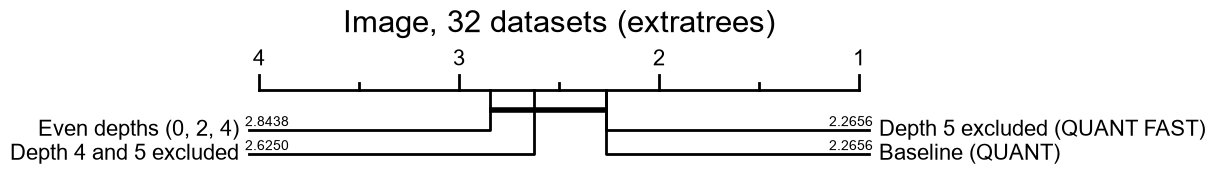

<StringArray>
['Baseline (QUANT)', 'Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)']
Length: 4, dtype: str
Baseline (QUANT)                 11.0
Depth 4 and 5 excluded            5.0
Depth 5 excluded (QUANT FAST)     3.0
Even depths (0, 2, 4)             4.0
dtype: float64
Depth 4 and 5 excluded           2.722222
Even depths (0, 2, 4)            2.629630
Depth 5 excluded (QUANT FAST)    2.351852
Baseline (QUANT)                 2.296296
dtype: float64
('Baseline (QUANT)', 'Even depths (0, 2, 4)', np.float64(0.05611708972983455), False)
('Baseline (QUANT)', 'Depth 4 and 5 excluded', np.float64(0.12120771449214225), False)
('Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', np.float64(0.15617973895268164), False)
('Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)', np.float64(0.2024462233511679), False)
('Baseline (QUANT)', 'Depth 5 excluded (QUANT FAST)', np.float64(0.4933694050024321), False)
('Depth 4 and 5 excluded', 'Even depths (0, 2

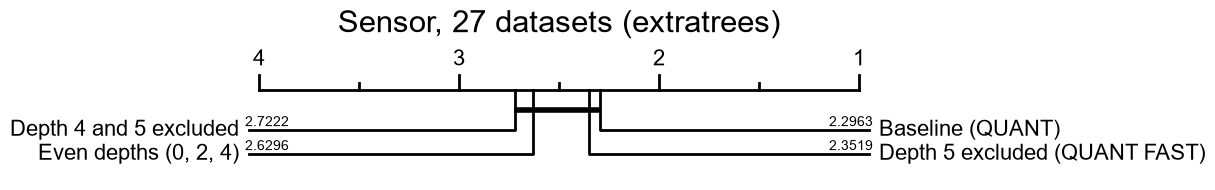

<StringArray>
['Baseline (QUANT)', 'Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)']
Length: 4, dtype: str
Baseline (QUANT)                 3.0
Depth 4 and 5 excluded           8.0
Depth 5 excluded (QUANT FAST)    3.0
Even depths (0, 2, 4)            2.0
dtype: float64
Even depths (0, 2, 4)            2.970588
Baseline (QUANT)                 2.676471
Depth 4 and 5 excluded           2.205882
Depth 5 excluded (QUANT FAST)    2.147059
dtype: float64
('Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)', np.float64(0.06475259508184217), False)
('Depth 4 and 5 excluded', 'Even depths (0, 2, 4)', np.float64(0.07977367412402309), False)
('Baseline (QUANT)', 'Depth 5 excluded (QUANT FAST)', np.float64(0.2557754175895596), False)
('Baseline (QUANT)', 'Even depths (0, 2, 4)', np.float64(0.42083506994660747), False)
('Baseline (QUANT)', 'Depth 4 and 5 excluded', np.float64(0.6024607516783109), False)
('Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)

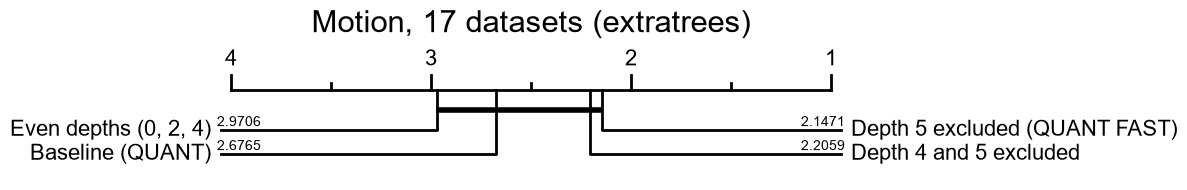

<StringArray>
['Baseline (QUANT)', 'Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)']
Length: 4, dtype: str
Baseline (QUANT)                 0.0
Depth 4 and 5 excluded           4.0
Depth 5 excluded (QUANT FAST)    1.0
Even depths (0, 2, 4)            3.0
dtype: float64
Baseline (QUANT)                 2.833333
Depth 5 excluded (QUANT FAST)    2.777778
Even depths (0, 2, 4)            2.444444
Depth 4 and 5 excluded           1.944444
dtype: float64
('Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', np.float64(0.12890625), False)
('Baseline (QUANT)', 'Depth 4 and 5 excluded', np.float64(0.1484375), False)
('Baseline (QUANT)', 'Even depths (0, 2, 4)', np.float64(0.30078125), False)
('Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)', np.float64(0.5703125), False)
('Baseline (QUANT)', 'Depth 5 excluded (QUANT FAST)', np.float64(0.91015625), False)
('Depth 4 and 5 excluded', 'Even depths (0, 2, 4)', np.float64(0.91015625), False)
Index(['Bas

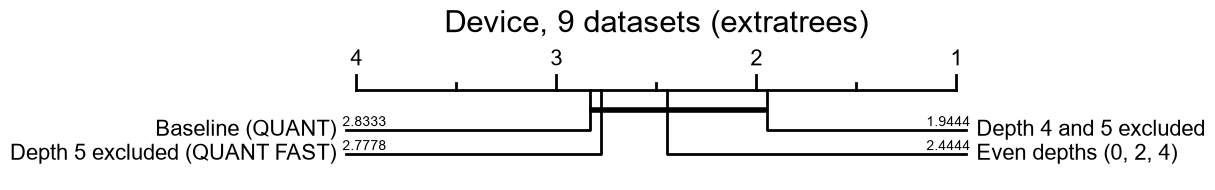

<StringArray>
['Baseline (QUANT)', 'Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)']
Length: 4, dtype: str
Baseline (QUANT)                 0.0
Depth 4 and 5 excluded           4.0
Depth 5 excluded (QUANT FAST)    1.0
Even depths (0, 2, 4)            1.0
dtype: float64
Baseline (QUANT)                 3.000
Even depths (0, 2, 4)            2.625
Depth 5 excluded (QUANT FAST)    2.375
Depth 4 and 5 excluded           2.000
dtype: float64
('Depth 4 and 5 excluded', 'Even depths (0, 2, 4)', np.float64(0.25), False)
('Baseline (QUANT)', 'Depth 4 and 5 excluded', np.float64(0.59375), False)
('Baseline (QUANT)', 'Depth 5 excluded (QUANT FAST)', np.float64(0.796875), False)
('Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', np.float64(0.796875), False)
('Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)', np.float64(0.90625), False)
('Baseline (QUANT)', 'Even depths (0, 2, 4)', np.float64(1.0), False)
Index(['Baseline (QUANT)', 'Even depths (0, 

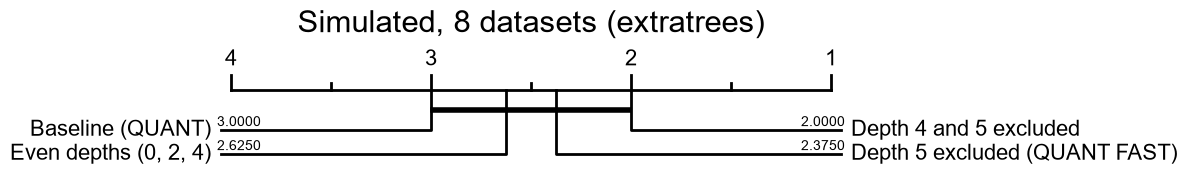

<StringArray>
['Baseline (QUANT)', 'Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)']
Length: 4, dtype: str
Baseline (QUANT)                 5.0
Depth 4 and 5 excluded           0.0
Depth 5 excluded (QUANT FAST)    1.0
Even depths (0, 2, 4)            1.0
dtype: float64
Depth 4 and 5 excluded           3.625
Even depths (0, 2, 4)            2.750
Depth 5 excluded (QUANT FAST)    2.000
Baseline (QUANT)                 1.625
dtype: float64
('Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', np.float64(0.0078125), True)
('Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)', np.float64(0.0625), False)
('Baseline (QUANT)', 'Depth 4 and 5 excluded', np.float64(0.078125), False)
('Baseline (QUANT)', 'Depth 5 excluded (QUANT FAST)', np.float64(0.09375), False)
('Depth 4 and 5 excluded', 'Even depths (0, 2, 4)', np.float64(0.109375), False)
('Baseline (QUANT)', 'Even depths (0, 2, 4)', np.float64(0.125), False)
Index(['Depth 4 and 5 excluded', 'Even 

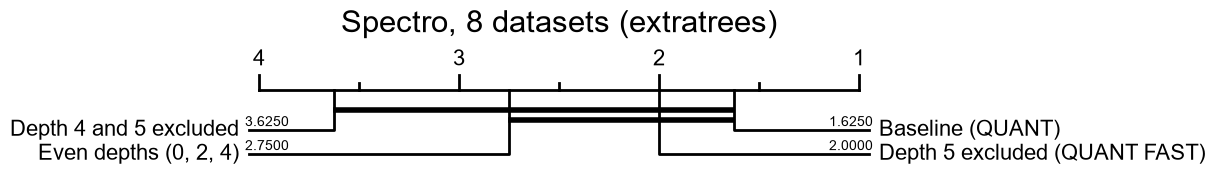

Skipping ECG (extratrees): only 6 datasets (MIN_DATASETS_PER_GROUP = 8).
<StringArray>
['Baseline (QUANT)', 'Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)']
Length: 4, dtype: str
Baseline (QUANT)                 4.0
Depth 4 and 5 excluded           5.0
Depth 5 excluded (QUANT FAST)    3.0
Even depths (0, 2, 4)            1.0
dtype: float64
Even depths (0, 2, 4)            2.93750
Depth 4 and 5 excluded           2.68750
Baseline (QUANT)                 2.34375
Depth 5 excluded (QUANT FAST)    2.03125
dtype: float64
('Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)', np.float64(0.03593045135498508), False)
('Baseline (QUANT)', 'Even depths (0, 2, 4)', np.float64(0.058686841763548624), False)
('Baseline (QUANT)', 'Depth 5 excluded (QUANT FAST)', np.float64(0.21244942236265563), False)
('Depth 4 and 5 excluded', 'Even depths (0, 2, 4)', np.float64(0.3927593002722902), False)
('Baseline (QUANT)', 'Depth 4 and 5 excluded', np.float64(0.8969711281194

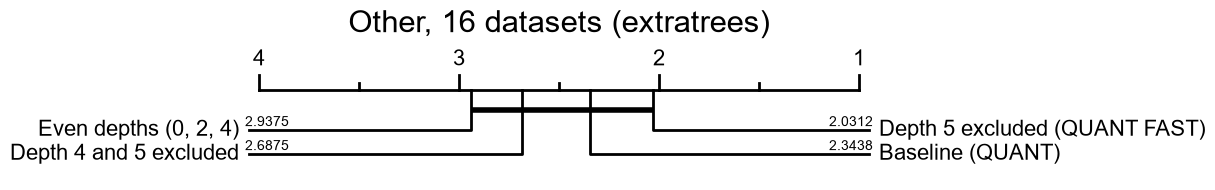

<StringArray>
['Baseline (QUANT)', 'Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)']
Length: 4, dtype: str
Baseline (QUANT)                 4.0
Depth 4 and 5 excluded           4.0
Depth 5 excluded (QUANT FAST)    5.0
Even depths (0, 2, 4)            5.0
dtype: float64
Depth 4 and 5 excluded           2.736842
Even depths (0, 2, 4)            2.684211
Baseline (QUANT)                 2.473684
Depth 5 excluded (QUANT FAST)    2.105263
dtype: float64
('Depth 5 excluded (QUANT FAST)', 'Even depths (0, 2, 4)', np.float64(0.156402587890625), False)
('Depth 4 and 5 excluded', 'Depth 5 excluded (QUANT FAST)', np.float64(0.4180412292480469), False)
('Baseline (QUANT)', 'Even depths (0, 2, 4)', np.float64(0.5152778625488281), False)
('Baseline (QUANT)', 'Depth 5 excluded (QUANT FAST)', np.float64(0.5865652352760775), False)
('Depth 4 and 5 excluded', 'Even depths (0, 2, 4)', np.float64(0.76800537109375), False)
('Baseline (QUANT)', 'Depth 4 and 5 excluded', np.

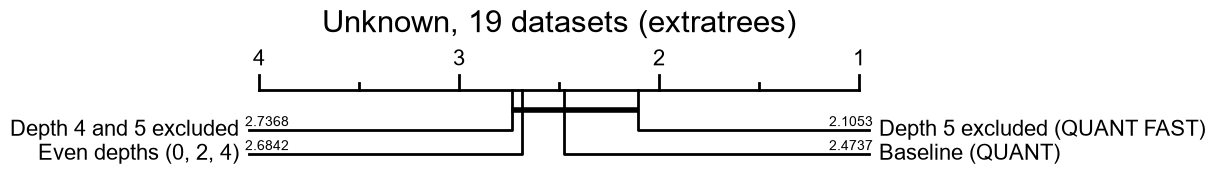

In [67]:
# CD diagram for each dataset-size group and each dataset type: all configurations, ranked within the group.
for grouping, (col, order) in GROUPINGS.items():
    for clf in classifiers:
        for group in order:
            in_group = table[(table["classifier"] == clf) & (table[col] == group)]
            n_ds = in_group["dataset"].nunique()
            short = re.split(r"\s{2}\(|\s\(n=", group)[0]          # "G1: 0–20th pct" or "Image"
            if n_ds < MIN_DATASETS_PER_GROUP:
                print(f"Skipping {short} ({clf}): only {n_ds} datasets (MIN_DATASETS_PER_GROUP = {MIN_DATASETS_PER_GROUP}).")
                continue
            df_perf = (
                in_group.rename(columns={"configuration": "classifier_name", "dataset": "dataset_name"})
                [["classifier_name", "dataset_name", "accuracy"]]
            )
            slug = re.sub(r"\W+", "_", short).strip("_")
            try:
                draw_cd_diagram(
                    df_perf=df_perf, alpha=CD_ALPHA, title=f"{short}, {n_ds} datasets ({clf})", labels=True,
                    filename=FIG_DIR / f"cd_{clf}_{col}_{slug}.png",
                )
            except RuntimeError as err:                             # Friedman test not significant in this group
                print(f"No diagram for {short} ({clf}): {err}")

### 9b. Datasets significantly different from the baseline (dataset by dataset)

For **each dataset** and each configuration, the baseline and the configuration are compared on the *same resamples* (paired), using the per-resample accuracies, and the datasets with a significant difference are counted. This is a per-dataset test, not a test across datasets.

- `PER_DATASET_TEST = "ttest"` is a paired t-test over the resamples. `"wilcoxon"` is the signed-rank test, but with **5 resamples its smallest possible two-sided p-value is 0.0625, so it can never be significant**; use it only with 6+ resamples (the `run.py` default is 30).
- Resamples share training data, so the variance is underestimated and p-values come out somewhat too small. Treat the counts as indicative, and prefer more resamples.
- Testing many datasets inflates false positives: at α = 0.05 about 5% of datasets are expected to come out "significant" by chance. The **BH-adjusted** columns control the false discovery rate across datasets and are the more trustworthy count.
- Identical differences in every resample give a t-test p-value of 0 (zero variance). For near-ceiling datasets check the size of the difference before counting it.

In [68]:
ALPHA = 0.05
PER_DATASET_TEST = "ttest"       # "ttest" or "wilcoxon"

def bh_adjust(p):
    # Benjamini-Hochberg adjusted p-values (false discovery rate)
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    scaled = p[order] * len(p) / np.arange(1, len(p) + 1)
    adjusted = np.minimum.accumulate(scaled[::-1])[::-1]
    out = np.empty(len(p))
    out[order] = np.minimum(adjusted, 1.0)
    return out

# One row per classifier x dataset x resample, one column per configuration (complete resample sets only).
wide = paired.pivot_table(index=["classifier", "dataset", "resample"], columns="configuration", values="accuracy")

rows = []
for (clf, ds), g in wide.groupby(level=["classifier", "dataset"]):
    for cfg in [c for c in wide.columns if c != BASELINE]:
        diff = (g[cfg] - g[BASELINE]).to_numpy()
        if len(diff) < 2 or np.allclose(diff, 0):
            p = 1.0                                   # identical results: no evidence of a difference
        elif PER_DATASET_TEST == "ttest":
            p = stats.ttest_rel(g[cfg], g[BASELINE]).pvalue
        else:
            p = stats.wilcoxon(diff).pvalue
        rows.append({"classifier": clf, "dataset": ds, "configuration": cfg, "n_resamples": len(diff),
                     "mean_diff_pp": 100 * diff.mean(), "p_value": 1.0 if np.isnan(p) else p})

per_dataset = pd.DataFrame(rows)
if PER_DATASET_TEST == "wilcoxon" and per_dataset["n_resamples"].min() < 6:
    print("WARNING: with fewer than 6 resamples a Wilcoxon test cannot reach p < 0.05; use 'ttest' or more resamples.")

per_dataset["p_adj_bh"] = per_dataset.groupby(["classifier", "configuration"])["p_value"].transform(bh_adjust)
per_dataset["sig"] = per_dataset["p_value"] < ALPHA
per_dataset["sig_bh"] = per_dataset["p_adj_bh"] < ALPHA
for grouping, (col, order) in GROUPINGS.items():
    per_dataset[col] = pd.Categorical(per_dataset["dataset"].map(dataset_groups[col]), categories=order, ordered=True)

def count_significant(frame, keys):
    rows = []
    for key, g in frame.groupby(keys, observed=True):
        key = key if isinstance(key, tuple) else (key,)
        rows.append({
            **dict(zip(keys, key)),
            "datasets": len(g),
            "better (p<α)": int((g["sig"] & (g["mean_diff_pp"] > 0)).sum()),
            "worse (p<α)": int((g["sig"] & (g["mean_diff_pp"] < 0)).sum()),
            "not significant": int((~g["sig"]).sum()),
            "better (BH)": int((g["sig_bh"] & (g["mean_diff_pp"] > 0)).sum()),
            "worse (BH)": int((g["sig_bh"] & (g["mean_diff_pp"] < 0)).sum()),
            "expected by chance": round(ALPHA * len(g), 1),
        })
    return pd.DataFrame(rows).set_index(keys)

print(f"Datasets with a significant difference from '{BASELINE}' ({PER_DATASET_TEST}, alpha = {ALPHA}):")
display(count_significant(per_dataset, ["classifier", "configuration"]))
for grouping, (col, order) in GROUPINGS.items():
    print(f"\nBy {grouping}:")
    display(count_significant(per_dataset, ["classifier", "configuration", col]))

print("\nDatasets that remain significant after BH correction:")
display(
    per_dataset.loc[per_dataset["sig_bh"], ["classifier", "configuration", "dataset", "size_group", "type_group",
                                            "mean_diff_pp", "p_value", "p_adj_bh"]]
    .sort_values(["classifier", "configuration", "p_adj_bh"]).round(4)
)

Datasets with a significant difference from 'Baseline (QUANT)' (ttest, alpha = 0.05):


datasets  better (p<α)  worse (p<α)  not significant  better (BH)  worse (BH)  expected by chance
classifier configuration                                                                                                                   
extratrees Depth 4 and 5 excluded              142            26           41               75           22          35                 7.1
           Depth 5 excluded (QUANT FAST)       142            17           18              107           11          12                 7.1
           Even depths (0, 2, 4)               142             9           48               85            6          39                 7.1


By size group:


datasets  better (p<α)  worse (p<α)  not significant  better (BH)  worse (BH)  expected by chance
classifier configuration                 size_group                                                                                                                                   
extratrees Depth 4 and 5 excluded        G1: 0–20th pct  (size 0.0104–0.0488, n=29)        29             2           10               17            1           7                 1.5
                                         G2: 20–40th pct  (size 0.0493–0.075, n=28)        28             0            7               21            0           7                 1.4
                                         G3: 40–60th pct  (size 0.0758–0.123, n=28)        28             5            9               14            5           8                 1.4
                                         G4: 60–80th pct  (size 0.125–0.193, n=28)         28             9            6               13            7           5                 1.4
                                         G5: 80–100th pct  (size 0.221–1.83, n=29)         29            10            9               10            9           8                 1.5
           Depth 5 excluded (QUANT FAST) G1: 0–20th pct  (size 0.0104–0.0488, n=29)        29             2            2               25            1           1                 1.5
                                         G2: 20–40th pct  (size 0.0493–0.075, n=28)        28             1            4               23            1           3                 1.4
                                         G3: 40–60th pct  (size 0.0758–0.123, n=28)        28             2            6               20            2           4                 1.4
                                         G4: 60–80th pct  (size 0.125–0.193, n=28)         28             6            1               21            5           1                 1.4
                                         G5: 80–100th pct  (size 0.221–1.83, n=29)         29             6            5               18            2           3                 1.5
           Even depths (0, 2, 4)         G1: 0–20th pct  (size 0.0104–0.0488, n=29)        29             1            9               19            1           6                 1.5
                                         G2: 20–40th pct  (size 0.0493–0.075, n=28)        28             1            8               19            0           6                 1.4
                                         G3: 40–60th pct  (size 0.0758–0.123, n=28)        28             1           13               14            1          11                 1.4
                                         G4: 60–80th pct  (size 0.125–0.193, n=28)         28             3            6               19            3           4                 1.4
                                         G5: 80–100th pct  (size 0.221–1.83, n=29)         29             3           12               14            1          12                 1.5


By dataset type:


datasets  better (p<α)  worse (p<α)  not significant  better (BH)  worse (BH)  expected by chance
classifier configuration                 type_group                                                                                                        
extratrees Depth 4 and 5 excluded        Image (n=32)           32             5           10               17            4           9                 1.6
                                         Sensor (n=27)          27             4            8               15            3           7                 1.4
                                         Motion (n=17)          17             3            3               11            3           1                 0.9
                                         Device (n=9)            9             4            1                4            3           1                 0.5
                                         Simulated (n=8)         8             2            1                5            2           1                 0.4
                                         Spectro (n=8)           8             0            5                3            0           5                 0.4
                                         ECG (n=6)               6             0            5                1            0           5                 0.3
                                         Other (n=16)           16             5            5                6            5           4                 0.8
                                         Unknown (n=19)         19             3            3               13            2           2                 1.0
           Depth 5 excluded (QUANT FAST) Image (n=32)           32             3            7               22            1           4                 1.6
                                         Sensor (n=27)          27             2            5               20            1           3                 1.4
                                         Motion (n=17)          17             5            1               11            3           0                 0.9
                                         Device (n=9)            9             2            0                7            2           0                 0.5
                                         Simulated (n=8)         8             0            0                8            0           0                 0.4
                                         Spectro (n=8)           8             1            2                5            1           2                 0.4
                                         ECG (n=6)               6             0            2                4            0           2                 0.3
                                         Other (n=16)           16             2            1               13            2           1                 0.8
                                         Unknown (n=19)         19             2            0               17            1           0                 1.0
           Even depths (0, 2, 4)         Image (n=32)           32             2           12               18            1           9                 1.6
                                         Sensor (n=27)          27             2            9               16            2           6                 1.4
                                         Motion (n=17)          17             1            4               12            1           2                 0.9
                                         Device (n=9)            9             2            1                6            1           1                 0.5
                                         Simulated (n=8)         8             0            3                5            0           3                 0.4
                                         Spectro (n=8)           8             0            5                3            0           5                 0.4
  


Datasets that remain significant after BH correction:


,classifier,configuration,dataset,size_group,type_group,mean_diff_pp,p_value,p_adj_bh
54,extratrees,Depth 4 and 5 excluded,ChlorineConcentration,"G3: 40–60th pct (size 0.0758–0.123, n=28)",Sensor (n=27),-2.9444,0.0000,0.0000
81,extratrees,Depth 4 and 5 excluded,Crop,"G4: 60–80th pct (size 0.125–0.193, n=28)",Image (n=32),-1.1131,0.0000,0.0000
219,extratrees,Depth 4 and 5 excluded,InsectWingbeatSound,"G3: 40–60th pct (size 0.0758–0.123, n=28)",Sensor (n=27),-2.9495,0.0000,0.0000
129,extratrees,Depth 4 and 5 excluded,EthanolLevel,"G5: 80–100th pct (size 0.221–1.83, n=29)",Spectro (n=8),-4.6400,0.0000,0.0000
267,extratrees,Depth 4 and 5 excluded,NonInvasiveFetalECGThorax1,"G5: 80–100th pct (size 0.221–1.83, n=29)",ECG (n=6),-0.7549,0.0000,0.0000
...,...,...,...,...,...,...,...,...
308,extratrees,"Even depths (0, 2, 4)",PowerCons,"G2: 20–40th pct (size 0.0493–0.075, n=28)",Other (n=16),-0.3889,0.0113,0.0393
5,extratrees,"Even depths (0, 2, 4)",AconityMINIPrinterLarge_eq,"G5: 80–100th pct (size 0.221–1.83, n=29)",Unknown (n=19),-0.1745,0.0125,0.0423
221,extratrees,"Even depths (0, 2, 4)",InsectWingbeatSound,"G3: 40–60th pct (size 0.0758–0.123, n=28)",Sensor (n=27),-0.3956,0.0134,0.0444
110,extratrees,"Even depths (0, 2, 4)",ECG5000,"G3: 40–60th pct (size 0.0758–0.123, n=28)",ECG (n=6),-0.0593,0.0145,0.0467


## 10. Accuracy vs training time graph

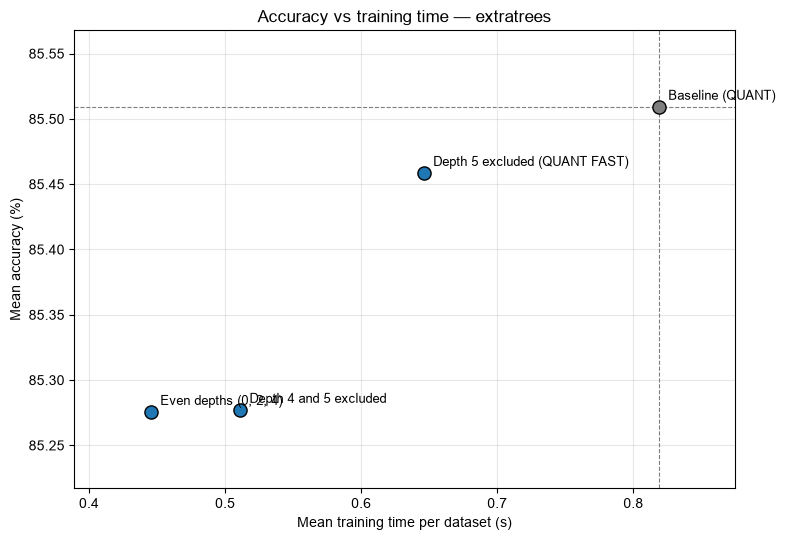

In [69]:
# ===== Accuracy vs training time: one point per experiment (original configurations only) =====
ACC_COL, TIME_COL = "accuracy", "time_train_total"        # columns in `table`
order = list(dict.fromkeys(CONFIG_LABELS.values()))

for clf in classifiers:
    sub = table[table["classifier"] == clf]
    means = (sub.groupby("configuration", observed=True)[[ACC_COL, TIME_COL]].mean()
                .reindex([c for c in order if c in set(sub["configuration"])]))
    acc = 100 * means[ACC_COL]
    time_ = means[TIME_COL]

    fig, ax = plt.subplots(figsize=(8, 5.5))
    for cfg in means.index:
        is_base = cfg == BASELINE
        ax.scatter(time_[cfg], acc[cfg], s=90, color="tab:gray" if is_base else "tab:blue",
                   edgecolor="black", zorder=3)
        ax.annotate(cfg, (time_[cfg], acc[cfg]), xytext=(7, 5), textcoords="offset points", fontsize=9)

    # Dashed guides through the baseline: left of the vertical line = faster, above the horizontal line = more accurate.
    ax.axvline(time_[BASELINE], color="tab:gray", linestyle="--", linewidth=0.8)
    ax.axhline(acc[BASELINE], color="tab:gray", linestyle="--", linewidth=0.8)

    ax.set(xlabel="Mean training time per dataset (s)",
           ylabel="Mean accuracy (%)",
           title=f"Accuracy vs training time — {clf}")
    ax.margins(x=0.15, y=0.25)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"accuracy_vs_time_{clf}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [70]:
# ===== Single-depth removal (leave-one-depth-out): load and pair the runs =====
# Reuses RESULTS_DIR, CONFIG_LABELS, BASELINE, REQUIRED, NUMERIC and TIME_AGG from the main analysis.
ABLATION_DEPTHS = range(0, 6)
ABLATION_LABELS = {f"no_depth_{d}": f"No depth {d}" for d in ABLATION_DEPTHS}   # CSV stem -> label
# (no_depth_6 is the same experiment as "Depth 6 excluded" above; it is simply loaded again here.)

baseline_stem = next(stem for stem, label in CONFIG_LABELS.items() if label == BASELINE)
abl_stems = {baseline_stem: BASELINE, **ABLATION_LABELS}

abl_frames = []
for stem, label in abl_stems.items():
    path = RESULTS_DIR / f"{stem}.csv"
    try:
        frame_ = pd.read_csv(path)
    except Exception as exc:
        print(f"Skipping {path.name}: {exc}")
        continue
    missing_cols = sorted(REQUIRED - set(frame_.columns))
    if missing_cols:
        print(f"Skipping {path.name}: missing columns {missing_cols}")
        continue
    frame_["configuration"] = label
    for col in NUMERIC:
        frame_[col] = pd.to_numeric(frame_[col], errors="coerce") if col in frame_ else np.nan
    frame_["resample"] = pd.to_numeric(frame_["resample"], errors="coerce")
    frame_["status"] = frame_["status"].fillna("").astype(str)
    abl_frames.append(frame_)

abl_results = pd.concat(abl_frames, ignore_index=True, sort=False)
if CLASSIFIERS is not None:
    abl_results = abl_results[abl_results["classifier"].isin(CLASSIFIERS)]
abl_results = abl_results.drop_duplicates(["configuration", "dataset", "classifier", "resample"])

abl_ok = abl_results[abl_results["status"].str.lower().eq("ok") & abl_results["accuracy"].notna()].copy()
abl_ok["time_train_total"] = abl_ok["time_transform_train"] + abl_ok["time_fit"]
abl_ok["time_test_total"] = abl_ok["time_transform_test"] + abl_ok["time_predict"]

# Keep only resamples that succeeded in every loaded configuration (paired splits).
abl_configs = sorted(abl_ok["configuration"].unique())
absent = [label for label in abl_stems.values() if label not in abl_configs]
if absent:
    print("WARNING: no usable results for:", absent)
n_cfg = abl_ok.groupby(["dataset", "classifier", "resample"])["configuration"].transform("nunique")
abl_paired = abl_ok[n_cfg == len(abl_configs)].copy()
print(f"{len(abl_configs)} configurations; kept {len(abl_paired):,} of {len(abl_ok):,} successful runs "
      f"({abl_paired['dataset'].nunique()} datasets).")

abl_spec = {
    "accuracy": ("accuracy", "mean"), "balanced_accuracy": ("balanced_accuracy", "mean"),
    "n_features": ("n_features", "mean"), "n_resamples": ("resample", "nunique"),
    "time_train_total": ("time_train_total", TIME_AGG), "time_test_total": ("time_test_total", TIME_AGG),
}
abl_table = abl_paired.groupby(["dataset", "classifier", "configuration"], as_index=False).agg(**abl_spec)
abl_table["error"] = 1 - abl_table["accuracy"]
display(abl_table.groupby("configuration").agg(datasets=("dataset", "nunique"),
                                               resamples_min=("n_resamples", "min"),
                                               resamples_max=("n_resamples", "max")))

7 configurations; kept 29,820 of 29,820 successful runs (142 datasets).


,datasets,resamples_min,resamples_max
configuration,,,
Baseline (QUANT),142,30,30
No depth 0,142,30,30
No depth 1,142,30,30
No depth 2,142,30,30
No depth 3,142,30,30
No depth 4,142,30,30
No depth 5,142,30,30


In [71]:
# ===== Per-dataset comparison with the baseline (same quantities as section 5) =====
ABL_BASE_COLS = ["accuracy", "error", "n_features", "time_train_total", "time_test_total"]
abl_base = (abl_table[abl_table["configuration"] == BASELINE]
            .set_index(["dataset", "classifier"])[ABL_BASE_COLS].add_prefix("base_"))
abl_cmp = (abl_table[abl_table["configuration"] != BASELINE]
           .join(abl_base, on=["dataset", "classifier"]).dropna(subset=["base_accuracy"]).copy())

abl_cmp["acc_diff_pp"] = 100 * (abl_cmp["accuracy"] - abl_cmp["base_accuracy"])
abl_cmp["error_reduction_pct"] = pct_reduction(abl_cmp["error"], abl_cmp["base_error"])
abl_cmp["log2_error_ratio"] = np.log2((abl_cmp["error"] + ERROR_EPS) / (abl_cmp["base_error"] + ERROR_EPS))
abl_cmp["feature_reduction_pct"] = pct_reduction(abl_cmp["n_features"], abl_cmp["base_n_features"])
abl_cmp["train_time_reduction_pct"] = pct_reduction(abl_cmp["time_train_total"], abl_cmp["base_time_train_total"])
abl_cmp["test_time_reduction_pct"] = pct_reduction(abl_cmp["time_test_total"], abl_cmp["base_time_test_total"])

# Groups (dataset size and dataset type) from the main analysis, and depth order for tables/plots.
for col, order in GROUPINGS.values():
    abl_cmp[col] = pd.Categorical(abl_cmp["dataset"].map(dataset_groups[col]), categories=order, ordered=True)
ABL_PRESENT = [label for label in ABLATION_LABELS.values() if label in set(abl_cmp["configuration"])]
abl_cmp["configuration"] = pd.Categorical(abl_cmp["configuration"], categories=ABL_PRESENT, ordered=True)
ABL_SHORT = {label: label.replace("No depth ", "") for label in ABL_PRESENT}      # "No depth 3" -> "3"

In [72]:
# ===== Per-dataset comparison with the baseline (same quantities as section 5) =====
ABL_BASE_COLS = ["accuracy", "error", "n_features", "time_train_total", "time_test_total"]
abl_base = (abl_table[abl_table["configuration"] == BASELINE]
            .set_index(["dataset", "classifier"])[ABL_BASE_COLS].add_prefix("base_"))
abl_cmp = (abl_table[abl_table["configuration"] != BASELINE]
           .join(abl_base, on=["dataset", "classifier"]).dropna(subset=["base_accuracy"]).copy())

abl_cmp["acc_diff_pp"] = 100 * (abl_cmp["accuracy"] - abl_cmp["base_accuracy"])
abl_cmp["error_reduction_pct"] = pct_reduction(abl_cmp["error"], abl_cmp["base_error"])
abl_cmp["log2_error_ratio"] = np.log2((abl_cmp["error"] + ERROR_EPS) / (abl_cmp["base_error"] + ERROR_EPS))
abl_cmp["feature_reduction_pct"] = pct_reduction(abl_cmp["n_features"], abl_cmp["base_n_features"])
abl_cmp["train_time_reduction_pct"] = pct_reduction(abl_cmp["time_train_total"], abl_cmp["base_time_train_total"])
abl_cmp["test_time_reduction_pct"] = pct_reduction(abl_cmp["time_test_total"], abl_cmp["base_time_test_total"])

# Groups (dataset size and dataset type) from the main analysis, and depth order for tables/plots.
for col, order in GROUPINGS.values():
    abl_cmp[col] = pd.Categorical(abl_cmp["dataset"].map(dataset_groups[col]), categories=order, ordered=True)
ABL_PRESENT = [label for label in ABLATION_LABELS.values() if label in set(abl_cmp["configuration"])]
abl_cmp["configuration"] = pd.Categorical(abl_cmp["configuration"], categories=ABL_PRESENT, ordered=True)
ABL_SHORT = {label: label.replace("No depth ", "") for label in ABL_PRESENT}      # "No depth 3" -> "3"

In [73]:
# ===== Which depths matter most? Ranking by mean accuracy change when the depth is removed =====
def holm(p):
    # Holm-adjusted p-values (family = the depths tested); NaNs are left as NaN.
    p = pd.Series(p, dtype=float)
    out = pd.Series(np.nan, index=p.index)
    valid = p.dropna().sort_values()
    m = len(valid)
    out[valid.index] = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * valid.to_numpy()))
    return out

abl_summary = summarise(abl_cmp, ["classifier", "configuration"])
abl_summary["Wilcoxon p (Holm)"] = abl_summary.groupby("classifier")["Wilcoxon p"].transform(holm)
# 1 = removing this depth hurts accuracy the most
abl_summary["importance rank"] = abl_summary.groupby("classifier")["acc diff mean (pp)"].rank(method="min").astype(int)

cols = ["classifier", "configuration", "importance rank", "datasets", "acc diff mean (pp)", "95% CI",
        "acc diff median (pp)", "improved", "tied", "declined", "Wilcoxon p", "Wilcoxon p (Holm)",
        "smoothed error ratio (geo. mean)", "feature red. mean (%)", "train time red. mean (%)",
        "test time red. mean (%)"]
display(abl_summary.sort_values(["classifier", "importance rank"])[cols].round(4).reset_index(drop=True))

,classifier,configuration,importance rank,datasets,acc diff mean (pp),95% CI,acc diff median (pp),improved,tied,declined,Wilcoxon p,Wilcoxon p (Holm),smoothed error ratio (geo. mean),feature red. mean (%),train time red. mean (%),test time red. mean (%)
0,extratrees,No depth 0,1,142,-0.3150,"[-0.51, -0.16]",-0.0350,55,10,77,0.0005,0.0020,1.0306,9.3477,3.5593,4.6503
1,extratrees,No depth 1,2,142,-0.1771,"[-0.30, -0.08]",-0.0580,51,6,85,0.0004,0.0020,1.0247,14.0844,11.6104,13.7172
2,extratrees,No depth 2,3,142,-0.0790,"[-0.15, -0.00]",-0.0848,40,5,97,0.0001,0.0006,1.0247,16.7131,14.9592,18.0282
3,extratrees,No depth 3,4,142,-0.0523,"[-0.11, 0.01]",-0.0243,54,5,83,0.0113,0.0338,1.0166,18.7231,16.7782,21.1145
4,extratrees,No depth 5,5,142,-0.0507,"[-0.13, 0.02]",0.0000,67,11,64,0.3439,0.3439,1.0100,21.1747,16.5795,26.0196
5,extratrees,No depth 4,6,142,-0.0498,"[-0.12, 0.02]",0.0000,68,6,68,0.1426,0.2852,1.0129,19.9569,18.5217,25.0919


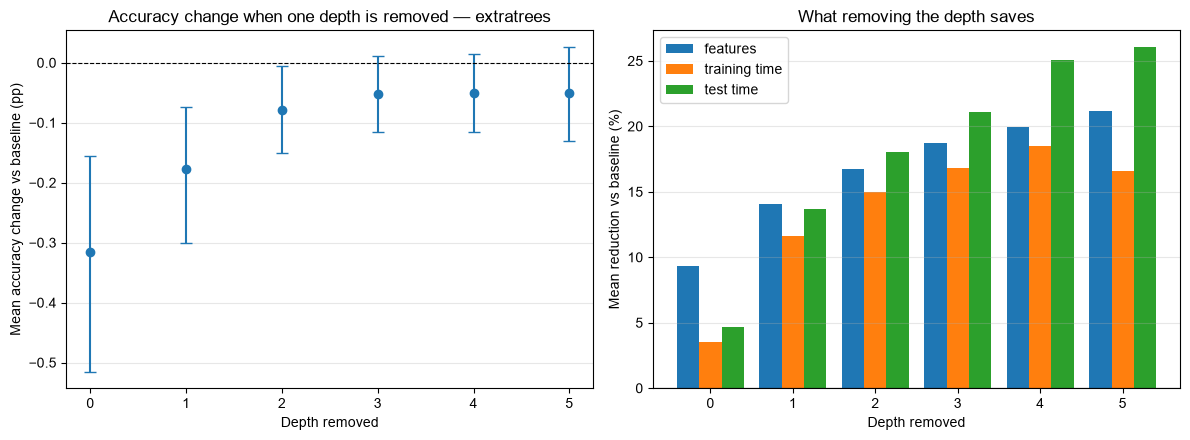

In [74]:
# ===== Accuracy change (with 95% CI) and cost saved, by depth removed =====
for clf in classifiers:
    sub = abl_cmp[abl_cmp["classifier"] == clf]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    for i, cfg in enumerate(ABL_PRESENT):
        d = sub.loc[sub["configuration"] == cfg, "acc_diff_pp"].to_numpy()
        if len(d) == 0:
            continue
        lo, hi = bootstrap_ci(d)
        ax1.errorbar(i, d.mean(), yerr=[[d.mean() - lo], [hi - d.mean()]], fmt="o", capsize=4, color="tab:blue")
    ax1.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax1.set_xticks(range(len(ABL_PRESENT)), [ABL_SHORT[c] for c in ABL_PRESENT])
    ax1.set(xlabel="Depth removed", ylabel="Mean accuracy change vs baseline (pp)",
            title=f"Accuracy change when one depth is removed — {clf}")
    ax1.grid(axis="y", alpha=0.3)

    cost = sub.groupby("configuration", observed=True)[["feature_reduction_pct", "train_time_reduction_pct",
                                                         "test_time_reduction_pct"]].mean().reindex(ABL_PRESENT)
    x = np.arange(len(ABL_PRESENT))
    for k, (colname, label) in enumerate([("feature_reduction_pct", "features"),
                                          ("train_time_reduction_pct", "training time"),
                                          ("test_time_reduction_pct", "test time")]):
        ax2.bar(x + (k - 1) * 0.27, cost[colname], width=0.27, label=label)
    ax2.axhline(0, color="black", linewidth=0.8)
    ax2.set_xticks(x, [ABL_SHORT[c] for c in ABL_PRESENT])
    ax2.set(xlabel="Depth removed", ylabel="Mean reduction vs baseline (%)", title="What removing the depth saves")
    ax2.legend()
    ax2.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()

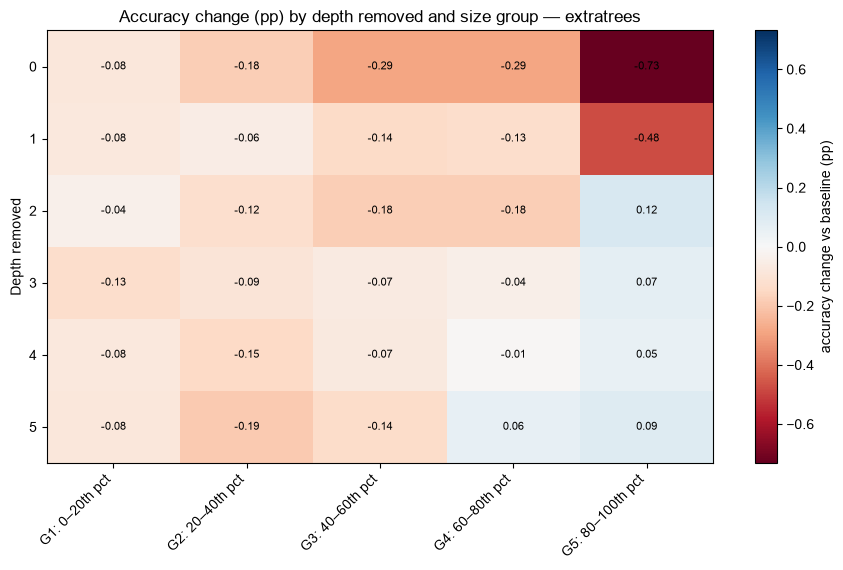

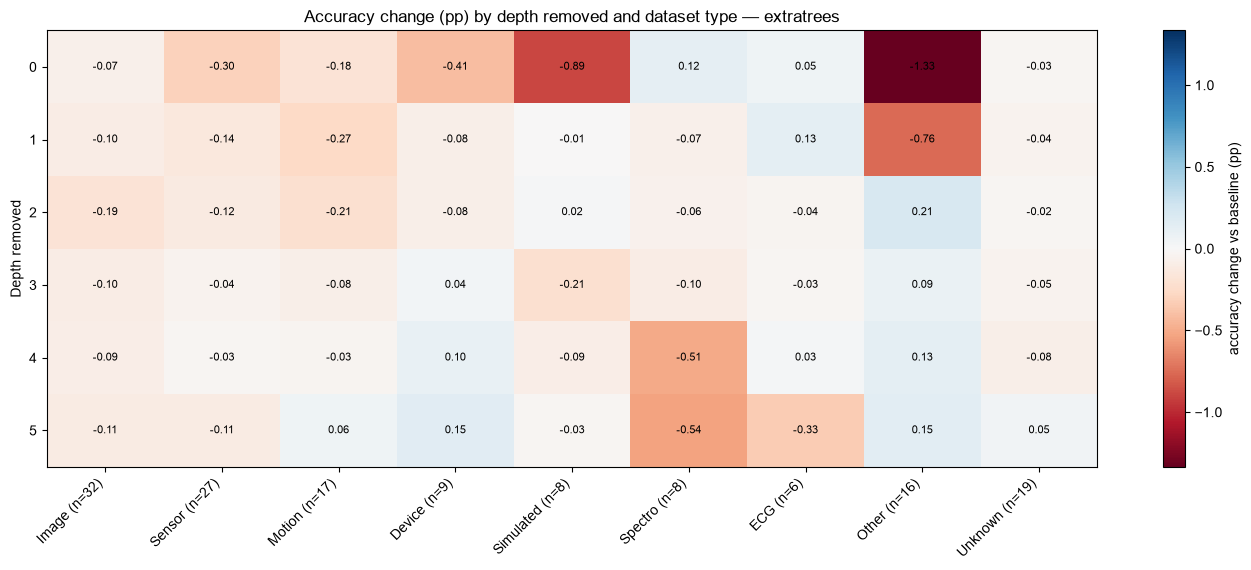

In [75]:
# ===== Does the importance of a depth depend on dataset type or size? =====
# Cell value = mean accuracy change (pp) when that depth is removed. Red = accuracy loss, blue = gain.
def short_group(name):
    return re.split(r"\s{2}\(", name)[0]          # drops the size range, keeps "G1: 0–20th pct" / "Image (n=32)"

for grouping, (col, order) in GROUPINGS.items():
    for clf in classifiers:
        mat = (abl_cmp[abl_cmp["classifier"] == clf]
               .pivot_table(index="configuration", columns=col, values="acc_diff_pp", aggfunc="mean", observed=True))
        mat = mat.reindex(index=ABL_PRESENT, columns=[g for g in order if g in mat.columns])
        lim = np.nanmax(np.abs(mat.to_numpy()))
        fig, ax = plt.subplots(figsize=(1.2 * mat.shape[1] + 3, 0.6 * mat.shape[0] + 2.2))
        im = ax.imshow(mat.to_numpy(), cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
        ax.set_xticks(range(mat.shape[1]), [short_group(g) for g in mat.columns], rotation=45, ha="right")
        ax.set_yticks(range(mat.shape[0]), [ABL_SHORT[c] for c in mat.index])
        for i in range(mat.shape[0]):
            for j in range(mat.shape[1]):
                if not np.isnan(mat.iat[i, j]):
                    ax.text(j, i, f"{mat.iat[i, j]:.2f}", ha="center", va="center", fontsize=8)
        ax.set(ylabel="Depth removed", title=f"Accuracy change (pp) by depth removed and {grouping} — {clf}")
        fig.colorbar(im, ax=ax, label="accuracy change vs baseline (pp)")
        fig.tight_layout()
        plt.show()

<StringArray>
['Baseline (QUANT)', 'No depth 0', 'No depth 1', 'No depth 2', 'No depth 3', 'No depth 4', 'No depth 5']
Length: 7, dtype: str
Baseline (QUANT)    14.0
No depth 0          22.0
No depth 1          21.0
No depth 2          13.0
No depth 3           7.0
No depth 4          20.0
No depth 5          33.0
dtype: float64
No depth 2          4.461268
No depth 0          4.302817
No depth 1          4.239437
No depth 3          4.102113
No depth 4          3.760563
No depth 5          3.623239
Baseline (QUANT)    3.510563
dtype: float64
('Baseline (QUANT)', 'No depth 2', np.float64(6.649861315988879e-05), True)
('Baseline (QUANT)', 'No depth 1', np.float64(0.0004296508413475711), True)
('Baseline (QUANT)', 'No depth 0', np.float64(0.0007771858948586537), True)
('Baseline (QUANT)', 'No depth 3', np.float64(0.01078181424418762), False)
('No depth 0', 'No depth 5', np.float64(0.02449281256097562), False)
('No depth 0', 'No depth 4', np.float64(0.038922423747895), False)
('No depth 1

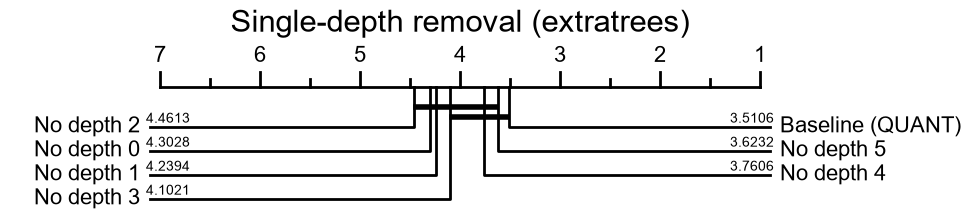

In [76]:
# ===== Critical difference diagram: baseline and every single-depth removal =====
for clf in classifiers:
    names = [BASELINE] + ABL_PRESENT
    df_perf = (abl_table[(abl_table["classifier"] == clf) & abl_table["configuration"].isin(names)]
               .rename(columns={"configuration": "classifier_name", "dataset": "dataset_name"})
               [["classifier_name", "dataset_name", "accuracy"]])
    try:
        draw_cd_diagram(df_perf=df_perf, alpha=CD_ALPHA, title=f"Single-depth removal ({clf})", labels=True,
                        filename=FIG_DIR / f"cd_{clf}_single_depth_removal.png")
    except RuntimeError as err:                      # Friedman test not significant
        print(f"No diagram ({clf}): {err}")

In [77]:
# ===== Do depths substitute for each other? Removing 5 and 6 together vs the sum of removing each alone =====
# interaction = (effect of removing both) - (effect of removing 5 alone + effect of removing 6 alone), per dataset.
# > 0: removing both costs LESS than the sum, i.e. the two depths are partly redundant.
PAIR_LABEL = "Depth 5 and 6 excluded"        # label from CONFIG_LABELS in the main analysis
needed = ["No depth 5", "No depth 6"]
if PAIR_LABEL in set(cmp["configuration"]) and all(n in ABL_PRESENT for n in needed):
    for clf in classifiers:
        single = (abl_cmp[(abl_cmp["classifier"] == clf) & abl_cmp["configuration"].isin(needed)]
                  .pivot_table(index="dataset", columns="configuration", values="acc_diff_pp", observed=True))
        both = cmp[(cmp["classifier"] == clf) & (cmp["configuration"] == PAIR_LABEL)].set_index("dataset")["acc_diff_pp"]
        inter = (both - single.sum(axis=1)).dropna()
        lo, hi = bootstrap_ci(inter.to_numpy())
        print(f"{clf}: removing 5 and 6 together = {both.mean():+.3f} pp; "
              f"sum of removing each alone = {single.sum(axis=1).mean():+.3f} pp")
        print(f"       interaction = {inter.mean():+.3f} pp, 95% CI [{lo:.3f}, {hi:.3f}] over {len(inter)} datasets")
else:
    print(f"Skipped: needs '{PAIR_LABEL}' in the main analysis and No depth 5 / No depth 6 loaded above.")

Skipped: needs 'Depth 5 and 6 excluded' in the main analysis and No depth 5 / No depth 6 loaded above.


# Analysis

As stated at the start of the notebook, the most promising tests are those that remove depths 5 (called $QUANT^{FAST}$ in the original paper), depths 4 and 5 and that only kept even depths. First, we will briefly clarify why the other experiments were disregarded.

## Removing early depths

Initial tests included removing depth 0 depth 0 and 1 intervals from feature extraction. The initial hypothesis was that such high level intervals (only 1 and 3 intevals respectively) is too substantial of a generalisation, and doesn't capture any of the original datasets shape.

Early testing proved these experiments to be worse than the original experiments overall. [EXPLAIN HOW]

These tests seem to prove the usefulness of longer intervals. Particularly, information provided by interval 0 essential serves as a summarisation of the entire sample, representing the median along with other upper and lower quantiles, which provide a good description of the overall distribution of the dataset. This early depth information has proven to be important across most datasets.

## Alternating depths, odd depths and even depths

These tests included only taking intervals at odd depth values (1, 3, 5), even depth values (0, 2, 4) and alternating between taking normal depth intervals (0, 2, 4) and shift depth intervals (1, 3, 5). The intial hypothesis of taking intervals in this way was that data represented by the removed depths could be represented by the depths above and below to enough of a degree to maintain accuracy while reducing the features needed.

Early experiments with only even depths proved to be beneficial overall, maintaining a reasonable level of accuracy while resulting in a substantial reduction in training time and feature count. [EXPLAIN HOW]

This method may have performed well overall since it maintained enough depth information to fairly represent the depths that were removed, while removing lower depths (3 and 5), which carry a substantial number of features compared to others.

Early tests with alternating depths proved the performance of this method to be reasonable, but was out performed by both the baseline performance and other experiment configuations. [EXPLAIN HOW]

This method may have suffered due to the removal of relational information between original and shifted intervals at each depth. Shifted intervals have the same length as normal intervals at each depth, so the model may be able to use this relationship to better understand the shape of the dataset.

Experimentation with only odd depths was conducted after the success of experimentation with even depths (0, 2, 4). However, this method resulted in reduced overall performance compared experimentation with even depths taken. [EXPLAIN HOW]

This method likely suffered in terms of accuracy compared to even depths experimenation due to the importance of the depths that were removed. Intial experimentation has already demonstrated the importance of depth 0 information (with its removal resulting in more substantial performance drop compared to later depth removal), and that depth 5 information is less relevant than other levels (indicated by the original papers $QUANT^{FAST}$ and our own no depth 5 experiment), meaning this implementation removes a highly relevant level while keeping a less relevant one. Even depths on the other had keeps depth 0, the more relevant depth, and removes depth 5, a less relevant level, likely resulting in its improved performance.

## Removing later depths

These experiments included removing depth 5, depth 4 and 5 and depth 3, 4 and 5 intervals from feature extraction. As stated previously, the removal of depth 5 only was done in the orginal quant paper, called $QUANT^{FAST}$, which was the main motivation behind this depth removal experimenation. The original paper indicated that performance gains reduced as lower depths were added, with substantially more features taken at each depth, which is why limiting the maximun depth to 6 (or 5 in the case of $QUANT^{FAST}$), was done. Specifically, this was the primary motivation for experimenting with the removal of depth 4 and 5, since the removal of later depths was suggested by the paper.

Removal of depth 5, as in $QUANT^{FAST}$, resulted in insignificant changes in accuracy overall while reducing feature and training times. [EXPLAIN HOW]

Removal of depts 4 and 5 resulted in a slight reduction in accuracy, but substantial gains in terms of training time and feature count reduction. [EXPLAIN HOW]

As previously mentioned, this is likely as a result of lower depths being less relavant compared to higher ones. 

The success of removing depth 4 and 5 presented 2 more questions. The first was to see if the idea proposed in the original paper, that later depths are less relevant, also holds in the case of the depths that were used in the final version. This assessment is done in the next section. The second was how far can we push this removal of earlier depths while still seeing improvements in performance. To assess this, an experiment was done with depths 3, 4 and 5 removed, to see if further end depth removal can still maintain reasonable accuracy levels while reducing computation.

Removal of depths 3, 4 and 5 resulted in a more sever reduction in accuracy compared to successful experiments, while not massively impacting training time (compared to other experiments). [EXPLAIN HOW]

This experiment indicats that setting a depth of 4 is the minimum depth to maintain performance, while depth 5 and 6 seem to be the limit for improving performance on average across the datasets assessed.

It should also be once again noted that setting the depth value to 6, or in the case of these experiments 5 or 4, does not nessessarily mean that intervals will be taken at all of these depths. These depths represented the maximum depths intervals can be taken from, but in any case where $d = log_2 n + 1$ for a dataset with samples of length $n$ is lower than these maximun depths, intervals will only be taken to as maximum of depth $d$.

## Per depth removal

These experiments were done with the main aim of attempting to assess the importance of each depth of intervals taken for classification. More specifically, these experiments aimed to evalute if the assessment made in the original paper, that depths beyond depth 5 (and 4 in the case of $QUANT^{FAST}$) were less relevant than early layers was also true for these earlier layers themselves. 

Results from these exeriments do seem to indicate this hypothesis as true, since larger intervals, taken at earlier depths do have a greater impact on performance than later ones, even in depths below 5. [EXPLAIN HOW]

This would seem to indicate that generalistaitons of the dataset distribution, rather than maintaing the dataset shape, is more informative for classification of the datasets in this assessment.

## Final results